# Algoritmo di Grover: studio sperimentale
## 1. Titolo e obiettivo del progetto
Studieremo amplificazione di ampiezza, overshooting e scaling con un'implementazione manuale in Python e Qiskit. Questo notebook costituisce la struttura iniziale per una futura relazione scientifica: in questa fase componiamo Grover con oracle e diffusore manuali e verifichiamo amplificazione e overshooting tramite Statevector.
Ora eseguiamo anche il primo esperimento statistico ideale con misure e 4096 shots.
La seconda modalità sperimentale aggiunge un modello depolarizzante Aer e lo studio del massimo noisy.
Le sezioni 11 e 12 studiano inoltre lo scaling ideale fino a n=7 e il caso di più soluzioni.

## 2. Descrizione sintetica dell'esperimento
Confronteremo la probabilità di trovare una soluzione marcata al variare delle iterazioni, del numero di qubit e del numero di soluzioni. Partiremo dalla simulazione ideale, aggiungeremo rumore e valuteremo eventualmente hardware IBM. Le funzioni high-level potranno servire in seguito come validazione.

Confrontiamo le verifiche esatte Statevector con frequenze da 4096 shots su Aer ideale. Il rumore viene studiato nella sezione 10; hardware reale resta uno sviluppo futuro.

## 3. Import e configurazione ambiente
Carichiamo solo le librerie necessarie alla struttura e alle verifiche dei due operatori e stampiamo le versioni per rendere tracciabile l'ambiente. Selezionare il kernel **Python (Grover)**, oppure l'interprete `.venv/Scripts/python.exe`.

Usiamo `AerSimulator` dal pacchetto separato `qiskit_aer`, compatibile con Qiskit 2.x; in questa fase usiamo `transpile` e `backend.run`. Riferimento: [documentazione ufficiale AerSimulator](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html). Importiamo anche i modelli di rumore Aer; non usiamo strumenti IBM o algoritmi preconfezionati.

In [1]:
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

LIBRARY_VERSIONS = {
    name: version(name)
    for name in ("qiskit", "qiskit-aer", "numpy", "pandas", "matplotlib")
}
print(f"Python: {sys.version.split()[0]}")
for name, installed_version in LIBRARY_VERSIONS.items():
    print(f"{name}: {installed_version}")
from qiskit.quantum_info import Operator, Statevector
from IPython.display import display
from qiskit import transpile
from time import perf_counter
from pathlib import Path
from collections.abc import Mapping
import json
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

Python: 3.12.0
qiskit: 2.5.2
qiskit-aer: 0.17.2
numpy: 2.4.4
pandas: 3.0.2
matplotlib: 3.10.9


## 4. Parametri globali
Centralizziamo i valori iniziali e il seme casuale. Gli stati sono stringhe nell'ordine Qiskit `q[n-1]...q[0]`: il bit più a destra corrisponde al qubit 0. Partiamo da una soluzione; la tupla consentirà di rappresentarne più di una.

Il seme sarà passato anche al simulatore e al transpiler nei futuri esperimenti. Non rende riproducibili rumore fisico o tempi di esecuzione.

In [2]:
RANDOM_SEED = 42
SHOTS_DEFAULT = 4096
N_VALUES = (2, 3, 4, 5, 6)  # Dimensioni per gli esperimenti ideali con shots.
N_QUBITS_DEFAULT = N_VALUES[1]
MARKED_STATE_DEFAULT = "101"
MARKED_STATES_DEFAULT = (MARKED_STATE_DEFAULT,)
SEARCH_SPACE_SIZE = 2 ** N_QUBITS_DEFAULT
N_SOLUTIONS_DEFAULT = len(MARKED_STATES_DEFAULT)

rng = np.random.default_rng(RANDOM_SEED)


def validate_problem(n: int, marked_states: list[str] | tuple[str, ...]) -> None:
    """Controlla dimensione, alfabeto binario e unicità delle soluzioni."""
    if isinstance(n, bool) or not isinstance(n, int) or n < 1:
        raise ValueError("n deve essere un intero positivo.")
    if not isinstance(marked_states, (list, tuple)):
        raise ValueError("marked_states deve essere una lista o tupla di bitstring.")
    if not marked_states:
        raise ValueError("Occorre almeno una soluzione marcata.")
    if any(not isinstance(state, str) or len(state) != n
           or set(state) - {"0", "1"} for state in marked_states):
        raise ValueError("Ogni stato deve essere una stringa binaria di lunghezza n.")
    if len(set(marked_states)) != len(marked_states):
        raise ValueError("Gli stati marcati devono essere distinti.")


def make_ideal_backend(seed: int = RANDOM_SEED) -> AerSimulator:
    """Crea un simulatore ideale riproducibile con la base di porte del progetto."""
    return AerSimulator(method="statevector", basis_gates=["u", "cx"], seed_simulator=seed)


validate_problem(N_QUBITS_DEFAULT, MARKED_STATES_DEFAULT)

### Tabella centrale degli esperimenti
Schema e impostazioni comuni per le esecuzioni con shots.

In [3]:
# Schema centrale: una riga per esecuzione statistica. Reset a ogni Run All.
RESULT_DTYPES = {
    "backend": "string", "mode": "string", "n": "Int64", "N": "Int64", "M": "Int64",
    "marked_states": "object", "k": "Int64", "shots": "Int64",
    "theoretical_probability": "Float64", "measured_success_probability": "Float64",
    "execution_time": "Float64", "depth": "Int64", "total_gate_count": "Int64",
    "two_qubit_gate_count": "Int64", "standard_error": "Float64",
    "seed": "Int64", "seed_transpiler": "Int64", "optimization_level": "Int64",
    "basis_gates": "object", "counts": "object", "normalized_counts": "object",
    "qiskit_version": "string", "qiskit_aer_version": "string",
}
RESULT_DTYPES.update({
    "p1": "Float64", "p2": "Float64", "readout_error": "Float64",
    "success_probability": "Float64", "expected_noisy_probability": "Float64",
    "actual_basis_gates": "string", "simulation_method": "string", "experiment_group": "string",
})
def make_results_dataframe() -> pd.DataFrame:
    return pd.DataFrame({name: pd.Series(dtype=dtype) for name, dtype in RESULT_DTYPES.items()})

results_df = make_results_dataframe()
IDEAL_BASIS_GATES = ("u", "cx")
IDEAL_OPTIMIZATION_LEVEL = 1

## 5. Costruzione dell'oracolo
Per uno stato marcato $O=I-2|w\rangle\langle w|$. L'ortonormalità della base dà
$O|x\rangle=(1-2\delta_{xw})|x\rangle$: solo l'ampiezza marcata cambia segno.
Per un insieme $W$ di stati distinti, $O_W=I-2\sum_{w\in W}|w\rangle\langle w|$.
Per ogni bitstring applichiamo X sui bit zero, una fase multi-controllata su
$|11\ldots1\rangle$, poi annulliamo gli X. Le riflessioni sui diversi stati marcati
si compongono senza interferire; i duplicati sono rifiutati perché annullerebbero il cambio di segno.

**Endianness:** le stringhe seguono l'ordine `q[n-1]...q[0]`: il bit a destra è il qubit 0.
`"101"` indica $q_2=1,q_1=0,q_0=1$ e l'indice `int("101", 2) = 5` nello Statevector.
`"001"` indica $q_2=0,q_1=0,q_0=1$, indice 1, non 4. Usiamo
`enumerate(reversed(state))` per associare caratteri e qubit. Nei diagrammi `q_0` è in alto.
Riferimento: [ordine dei bit in Qiskit](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

L'helper condiviso usa Z per n=1, CZ per n=2, e H–MCX–H sul target per n>=3.
Poiché $HXH=Z$, questa sequenza cambia segno solo quando tutti i qubit valgono 1.
Non usiamo ancille o GroverOperator.

In [4]:
def apply_multi_controlled_z(circuit: QuantumCircuit) -> None:
    """Applica in-place la fase -1 su |11...1> a tutti i qubit."""
    n = circuit.num_qubits
    if n < 1:
        raise ValueError("La Z multi-controllata richiede almeno un qubit.")
    if n == 1:
        circuit.z(0)
    elif n == 2:
        circuit.cz(0, 1)
    else:
        target = n - 1
        circuit.h(target)
        circuit.mcx(list(range(target)), target)
        circuit.h(target)


def build_phase_oracle(
    n_qubits: int, marked_states: list[str] | tuple[str, ...]
) -> QuantumCircuit:
    """Costruisce O_W; stringhe in ordine q[n-1]...q[0]."""
    validate_problem(n_qubits, marked_states)
    circuit = QuantumCircuit(n_qubits, name="O")
    for state in marked_states:
        zero_qubits = [q for q, bit in enumerate(reversed(state)) if bit == "0"]
        for q in zero_qubits:
            circuit.x(q)
        apply_multi_controlled_z(circuit)
        for q in reversed(zero_qubits):
            circuit.x(q)
    return circuit


def build_oracle(n: int, marked_states: list[str] | tuple[str, ...]) -> QuantumCircuit:
    """Alias compatibile con la firma già prevista nel notebook."""
    return build_phase_oracle(n, marked_states)

## 6. Costruzione del diffusore
Lo stato uniforme è $|s\rangle=H^{\otimes n}|0\ldots0\rangle$ e
$D=2|s\rangle\langle s|-I$. Scrivendo $|\psi\rangle=\alpha|s\rangle+|\psi_\perp\rangle$,
si ha $D|\psi\rangle=\alpha|s\rangle-|\psi_\perp\rangle$: la componente lungo lo stato
uniforme rimane invariata, quella ortogonale cambia segno. È una riflessione rispetto a $|s\rangle$.
Per $N=2^n$, ampiezze $a_x$ e media $\bar a=N^{-1}\sum_x a_x$, segue
$a'_x=2\bar a-a_x$ (**inversion about the mean**), anche per ampiezze complesse.

La sequenza H, X, multi-controlled Z, X, H realizza
$H^{\otimes n}(I-2|0\ldots0\rangle\langle0\ldots0|)H^{\otimes n}=-D$.
Includiamo `global_phase = np.pi` per ottenere esattamente $D$ e confrontare direttamente le ampiezze.
Una fase globale $e^{i\phi}$ non cambia le probabilità: $|e^{i\phi}a_x|^2=|a_x|^2$.
Le fasi relative tra componenti, invece, possono cambiare l'interferenza.

In [5]:
def build_diffuser(n_qubits: int) -> QuantumCircuit:
    """Costruisce D = 2|s><s| - I, inclusa la fase globale."""
    if isinstance(n_qubits, bool) or not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("n_qubits deve essere un intero positivo.")
    circuit = QuantumCircuit(n_qubits, name="D")
    circuit.h(range(n_qubits))
    circuit.x(range(n_qubits))
    apply_multi_controlled_z(circuit)
    circuit.x(range(n_qubits))
    circuit.h(range(n_qubits))
    circuit.global_phase = np.pi
    return circuit

### 6.1 Circuiti a tre qubit: stato marcato |101⟩
I diagrammi testuali mostrano le porte senza dipendenze grafiche aggiuntive.

In [29]:
oracle_example = build_phase_oracle(3, ["101"])
diffuser_example = build_diffuser(3)
print("Phase oracle, stato marcato |101>:")
print(oracle_example.draw(output="text"))
print("Diffusore (fase globale pi inclusa):")
print(diffuser_example.draw(output="text"))

Phase oracle, stato marcato |101>:
                    
q_0: ───────■───────
     ┌───┐  │  ┌───┐
q_1: ┤ X ├──■──┤ X ├
     ├───┤┌─┴─┐├───┤
q_2: ┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘
Diffusore (fase globale pi inclusa):
global phase: π
     ┌───┐┌───┐          ┌───┐┌───┐     
q_0: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤       │  ├───┤├───┤     
q_1: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐
q_2: ┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘└───┘└───┘└───┘└───┘


### 6.2 Verifica delle ampiezze e tabella
Prepariamo $|s\rangle$ con Hadamard e confrontiamo le ampiezze con formule indipendenti dai circuiti.
Per $N=8,M=1$, dopo l'oracolo $\bar a=3/(4\sqrt8)$; dopo il diffusore
l'ampiezza marcata vale $5/(2\sqrt8)$ e le altre $1/(2\sqrt8)$.
Gli assert usano tolleranza assoluta $10^{-12}$ e relativa zero.

In [7]:
ATOL = 1e-12
prepare_uniform = QuantumCircuit(3)
prepare_uniform.h(range(3))
before_oracle = Statevector.from_instruction(prepare_uniform)
after_oracle = before_oracle.evolve(oracle_example)
after_diffuser = after_oracle.evolve(diffuser_example)
expected_before = np.full(8, 1 / np.sqrt(8), dtype=complex)
expected_after = expected_before.copy()
expected_after[5] *= -1
expected_diffused = 2 * expected_after.mean() - expected_after
np.testing.assert_allclose(before_oracle.data, expected_before, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_oracle.data, expected_after, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_diffuser.data, expected_diffused, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_diffuser.data[5], 5 / (2 * np.sqrt(8)), atol=ATOL, rtol=0)
np.testing.assert_allclose(np.linalg.norm(after_diffuser.data), 1, atol=ATOL, rtol=0)
amplitudes_df = pd.DataFrame({
    "basis_state": [format(i, "03b") for i in range(8)],
    "amplitude_before_oracle": np.real_if_close(before_oracle.data),
    "amplitude_after_oracle": np.real_if_close(after_oracle.data),
    "amplitude_after_diffuser": np.real_if_close(after_diffuser.data),
})
display(amplitudes_df)

,basis_state,amplitude_before_oracle,amplitude_after_oracle,amplitude_after_diffuser
0,000,0.353553,0.353553,0.176777
1,001,0.353553,0.353553,0.176777
2,010,0.353553,0.353553,0.176777
3,011,0.353553,0.353553,0.176777
4,100,0.353553,0.353553,0.176777
5,101,0.353553,-0.353553,0.883883
6,110,0.353553,0.353553,0.176777
7,111,0.353553,0.353553,0.176777


## 7. Costruzione dell'algoritmo di Grover
QuantumCircuit parte da |0...0⟩; gli Hadamard preparano lo stato uniforme.
Ogni iterazione applica prima l'oracolo manuale, poi il diffusore manuale.
Con zero iterazioni rimane la sovrapposizione uniforme. Le misure opzionali associano
il qubit i al bit classico i, mantenendo le stringhe nell'ordine q[n-1]...q[0].
Per Statevector usiamo sempre measure=False.

In [9]:
def build_grover_circuit(
    n_qubits: int,
    marked_states: list[str] | tuple[str, ...],
    iterations: int,
    measure: bool = True,
) -> QuantumCircuit:
    """Prepara lo stato uniforme, applica (D O)^iterations e misura opzionalmente."""
    validate_problem(n_qubits, marked_states)
    if isinstance(iterations, bool) or not isinstance(iterations, (int, np.integer)) or iterations < 0:
        raise ValueError("iterations deve essere un intero non negativo.")
    if not isinstance(measure, bool):
        raise ValueError("measure deve essere booleano.")
    circuit = QuantumCircuit(n_qubits, n_qubits if measure else 0, name="Grover")
    circuit.h(range(n_qubits))
    if iterations:
        oracle = build_phase_oracle(n_qubits, marked_states)
        diffuser = build_diffuser(n_qubits)
        for _ in range(iterations):
            circuit.compose(oracle, inplace=True)
            circuit.compose(diffuser, inplace=True)
    if measure:
        circuit.measure(range(n_qubits), range(n_qubits))
    return circuit

## 8. Verifica teorica e geometria
Per $0<M<N$ definiamo $|G\rangle=M^{-1/2}\sum_{w\in W}|w\rangle$ e
$|B\rangle=(N-M)^{-1/2}\sum_{x\notin W}|x\rangle$.
Lo stato uniforme è $|s\rangle=\cos\theta|B\rangle+\sin\theta|G\rangle$,
con $\theta=\arcsin\sqrt{M/N}$ e $N=2^n$.
Oracle e diffusore mantengono lo stato nel sottospazio generato da $|B\rangle,|G\rangle$.
La loro composizione $DO$ ruota di $2\theta$ verso le soluzioni a ogni iterazione:
$$|\psi_k\rangle=\cos((2k+1)\theta)|B\rangle+\sin((2k+1)\theta)|G\rangle,$$
quindi $P(k)=\sin^2((2k+1)\theta)$. Oltre il primo massimo la rotazione allontana
lo stato dalla direzione delle soluzioni: è l'**overshooting**. La probabilità poi oscilla;
non diminuisce indefinitamente. Se $M=N$, il successo è sempre 1 e bastano zero iterazioni.

Il primo massimo continuo è $k_*=\pi/(4\theta)-1/2$. Per $M/N\ll1$,
$\theta\simeq\sqrt{M/N}$, dunque $k_*\simeq(\pi/4)\sqrt{N/M}-1/2$;
la comune stima $(\pi/4)\sqrt{N/M}$ trascura anche il termine $-1/2$.
La funzione sceglie l'intero non negativo con probabilità maggiore tra floor e ceil di $k_*$;
a parità numerica sceglie il minore. È la scelta vicino al **primo** massimo,
non una ricerca illimitata su eventuali massimi successivi.

Riferimenti fuori dalla slide del corso: [analisi geometrica](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/grover-algorithm/analysis)
e [scelta delle iterazioni](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/grover-algorithm/number-of-iterations), IBM Quantum. 

In [10]:
def grover_theta(N: int, M: int) -> float:
    """Restituisce arcsin(sqrt(M/N)); richiede 1 <= M <= N interi."""
    if any(isinstance(v, bool) or not isinstance(v, (int, np.integer)) for v in (N, M)):
        raise ValueError("N e M devono essere interi.")
    if N < 1 or not 1 <= M <= N:
        raise ValueError("Occorre 1 <= M <= N.")
    return float(np.arcsin(np.sqrt(M / N)))


def theoretical_success_probability(N: int, M: int, k: int) -> float:
    """Probabilità ideale dopo k iterazioni intere non negative."""
    theta = grover_theta(N, M)
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 0:
        raise ValueError("k deve essere un intero non negativo.")
    if M == N:
        return 1.0
    return float(np.sin((2 * k + 1) * theta) ** 2)


def optimal_grover_iterations(N: int, M: int) -> int:
    """Sceglie tra gli interi vicini al primo massimo; parità -> meno iterazioni."""
    theta = grover_theta(N, M)
    if M == N:
        return 0
    continuous = np.pi / (4 * theta) - 0.5
    lower = max(0, int(np.floor(continuous)))
    upper = max(0, int(np.ceil(continuous)))
    p_lower = theoretical_success_probability(N, M, lower)
    p_upper = theoretical_success_probability(N, M, upper)
    return upper if p_upper > p_lower + 1e-14 else lower


iteration_choices_df = pd.DataFrame([
    {"n": n, "N": 2 ** n, "M": 1,
     "approximate_k": np.pi / 4 * np.sqrt(2 ** n),
     "first_continuous_maximum": np.pi / (4 * grover_theta(2 ** n, 1)) - 0.5,
     "chosen_k": optimal_grover_iterations(2 ** n, 1)}
    for n in (2, 3, 4)
])
display(iteration_choices_df)

,n,N,M,approximate_k,first_continuous_maximum,chosen_k
0,2,4,1,1.570796,1.000000,1
1,3,8,1,2.221441,1.673408,2
2,4,16,1,3.141593,2.608269,3


## 9. Verifiche ideali con Statevector
Per $N=4,M=1$, $\theta=\pi/6$ e $3\theta=\pi/2$: una singola iterazione
produce lo stato marcato con probabilità 1. Verifichiamo anche le ampiezze dello stato completo.
La tabella confronta teoria e simulazione per n=2,3,4 e k=0,...,8, includendo il primo
massimo e l'overshooting. Il successo è la somma delle probabilità degli stati marcati.
Usiamo tolleranza assoluta $10^{-12}$ e relativa zero; non c'è incertezza da shots.

In [ ]:
special_state = Statevector.from_instruction(build_grover_circuit(2, ["01"], 1, False))
np.testing.assert_allclose(special_state.data, Statevector.from_label("01").data, atol=ATOL, rtol=0)
np.testing.assert_allclose(theoretical_success_probability(4, 1, 1), 1, atol=ATOL, rtol=0)
assert optimal_grover_iterations(4, 1) == 1
print(f"N=4, M=1, k=1: P(|01>) = {special_state.probabilities()[1]:.15f}")

single_solution_cases = {2: ["01"], 3: ["101"], 4: ["0101"]}
comparison_rows = []
for n, marked in single_solution_cases.items():
    N, M = 2 ** n, len(marked)
    indices = [int(state, 2) for state in marked]
    for k in range(9):
        state = Statevector.from_instruction(build_grover_circuit(n, marked, k, False))
        probability = float(state.probabilities()[indices].sum())
        theory = theoretical_success_probability(N, M, k)
        np.testing.assert_allclose(probability, theory, atol=ATOL, rtol=0)
        np.testing.assert_allclose(np.linalg.norm(state.data), 1, atol=ATOL, rtol=0)
        comparison_rows.append({
            "n": n, "N": N, "M": M, "k": k,
            "theoretical_probability": theory, "statevector_probability": probability,
            "absolute_error": abs(probability - theory),
        })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
print(f"Errore assoluto massimo: {comparison_df.absolute_error.max():.3e}")

# Regressioni: zero iterazioni, più soluzioni, n=1 e tutte le soluzioni.
for n, marked in ((1, ["0"]), (1, ["0", "1"]), (3, ["001", "110"])):
    for k in range(5):
        state = Statevector.from_instruction(build_grover_circuit(n, marked, k, False))
        np.testing.assert_allclose(
            state.probabilities()[[int(w, 2) for w in marked]].sum(),
            theoretical_success_probability(2 ** n, len(marked), k), atol=ATOL, rtol=0,
        )
zero_circuit = build_grover_circuit(3, ["001"], 0, False)
np.testing.assert_allclose(Statevector.from_instruction(zero_circuit).data,
                           np.full(8, 1 / np.sqrt(8)), atol=ATOL, rtol=0)
assert zero_circuit.num_clbits == 0
measured = build_grover_circuit(3, ["001"], 2)
measurements = [item for item in measured.data if item.operation.name == "measure"]
assert measured.num_clbits == 3 and len(measurements) == 3
assert [(measured.find_bit(item.qubits[0]).index, measured.find_bit(item.clbits[0]).index)
        for item in measurements] == [(0, 0), (1, 1), (2, 2)]
np.testing.assert_allclose(
    Operator(measured.remove_final_measurements(inplace=False)).data,
    Operator(build_grover_circuit(3, ["001"], 2, False)).data, atol=ATOL, rtol=0,
)
assert optimal_grover_iterations(8, 8) == 0
assert optimal_grover_iterations(8, 4) == 0  # Parità: P(k)=1/2.
for bad_call in (
    lambda: build_grover_circuit(2, ["01"], -1),
    lambda: build_grover_circuit(2, ["01"], 1.5),
    lambda: build_grover_circuit(2, ["01"], True),
    lambda: build_grover_circuit(2, ["01"], 1, "yes"),
    lambda: theoretical_success_probability(4, 1, -1),
    lambda: theoretical_success_probability(4, 1, 0.5),
    lambda: grover_theta(0, 1), lambda: grover_theta(4, 0),
    lambda: grover_theta(4, 5), lambda: grover_theta(4.0, 1),
):
    try:
        bad_call()
    except ValueError:
        pass
    else:
        raise AssertionError("Input non valido accettato.")
print("Il test conferma che il circuito quantistico costruito in Qiskit riproduce con infinita precisione la teoria dell'algoritmo di Grover.")

N=4, M=1, k=1: P(|01>) = 0.999999999999999


,n,N,M,k,theoretical_probability,statevector_probability,absolute_error
0,2,4,1,0,0.250000,0.250000,1.110223e-16
1,2,4,1,1,1.000000,1.000000,8.881784e-16
2,2,4,1,2,0.250000,0.250000,5.551115e-17
3,2,4,1,3,0.250000,0.250000,6.661338e-16
4,2,4,1,4,1.000000,1.000000,2.886580e-15
5,2,4,1,5,0.250000,0.250000,5.551115e-16
6,2,4,1,6,0.250000,0.250000,1.831868e-15
7,2,4,1,7,1.000000,1.000000,4.662937e-15
8,2,4,1,8,0.250000,0.250000,1.110223e-15
9,3,8,1,0,0.125000,0.125000,8.326673e-17


Errore assoluto massimo: 2.176e-14
Confronti ideali e controlli del circuito completo superati.


### 9.1 Primo esperimento statistico ideale
Ora passiamo dalle probabilità esatte alle **misure simulate**. Ogni circuito viene
eseguito 4096 volte (*shots*) su Aer, senza rumore.

Per ogni numero di qubit da 2 a 6 proviamo le iterazioni vicine al primo massimo
teorico. Lo stato cercato è sempre `00...01`.

L'esperimento segue tre passaggi:
1. Costruire e simulare il circuito di Grover.
2. Contare quante misure restituiscono lo stato cercato.
3. Confrontare la frequenza di successo con la probabilità teorica.

La frequenza è semplicemente **successi / shots**: per esempio, 3072 successi su
4096 misure danno 0,75. Con un numero finito di misure sono normali piccoli scarti
dalla teoria, anche senza rumore.

La funzione seguente raccoglie una singola esecuzione; la cella successiva la
ripete per i diversi valori di `n` e `k` e mostra una tabella riassuntiva.
I campi tecnici nel dizionario finale servono ai confronti e ai CSV delle sezioni
successive. L'errore standard stima la fluttuazione statistica della frequenza:
$\sqrt{\hat p(1-\hat p)/S}$. Non è un intervallo di confidenza; ai valori 0 e 1
si annulla senza dimostrare che l'incertezza sia nulla.


In [32]:
def success_probability(probabilities, marked_states):
    """Somma le probabilità degli stati cercati in una distribuzione normalizzata."""
    return float(sum(probabilities.get(state, 0.0) for state in marked_states))


def run_ideal_experiment(n_qubits, marked_states, iterations, shots, seed):
    """Simula Grover senza rumore e raccoglie il risultato."""
    # 1. Costruiamo il circuito e lo compiliamo per il simulatore.
    circuit = build_grover_circuit(n_qubits, marked_states, iterations, measure=True)
    backend = make_ideal_backend(seed)
    compiled = transpile(circuit, backend,
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=seed)

    # 2. Eseguiamo le misure e calcoliamo la frequenza di successo.
    start = perf_counter()
    result = backend.run(compiled, shots=shots, seed_simulator=seed).result()
    execution_time = perf_counter() - start  # Tempo del simulatore, non di una QPU.
    counts = dict(result.get_counts())
    successes = sum(counts.get(state, 0) for state in marked_states)
    measured = successes / shots

    # 3. Calcoliamo la probabilità teorica da confrontare con le misure.
    N, M = 2 ** n_qubits, len(marked_states)
    theory = theoretical_success_probability(N, M, iterations)

    # Dati di supporto per i successivi confronti di risorse e per i CSV.
    normalized = {state: count / shots for state, count in counts.items()}
    gates_only = compiled.remove_final_measurements(inplace=False)
    gate_instructions = list(gates_only.data)
    return {
        "backend": backend.name, "mode": "ideal_shots", "n": n_qubits, "N": N, "M": M,
        "marked_states": tuple(marked_states), "k": iterations, "shots": int(shots),
        "theoretical_probability": theory, "measured_success_probability": measured,
        "execution_time": execution_time,
        "depth": gates_only.depth(),
        "total_gate_count": len(gate_instructions),
        "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in gate_instructions),
        "standard_error": float(np.sqrt(measured * (1 - measured) / shots)),
        "seed": int(seed), "seed_transpiler": int(seed),
        "optimization_level": IDEAL_OPTIMIZATION_LEVEL, "basis_gates": IDEAL_BASIS_GATES,
        "counts": counts, "normalized_counts": normalized,
        "qiskit_version": LIBRARY_VERSIONS["qiskit"], "qiskit_aer_version": LIBRARY_VERSIONS["qiskit-aer"],
    }


In [34]:
# Ripetiamo l'esperimento vicino al massimo teorico, includendo il calo successivo.
experiment_rows = []
for n in N_VALUES:
    marked = (format(1, f"0{n}b"),)  # Stato cercato: 00...01.
    k_opt = optimal_grover_iterations(2 ** n, 1)
    for k in range(max(0, k_opt - 2), k_opt + 3):
        seed = RANDOM_SEED + 100 * n + k
        row = run_ideal_experiment(n, marked, k, SHOTS_DEFAULT, seed)
        experiment_rows.append(row)

# Conserviamo tutti i dati per le sezioni successive, ma mostriamo solo l'essenziale.
results_df = pd.DataFrame(experiment_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
summary = results_df[["n", "k", "shots", "theoretical_probability",
                      "measured_success_probability"]].copy()
summary.columns = ["Qubit", "Iterazioni", "Shots", "Probabilità teorica", "Frequenza misurata"]
display(summary.round(4))
print("Confrontando le ultime due colonne si possono notare i piccoli scarti.")
print("Per ogni numero di qubit, si osserva inoltre la crescita e il calo del successo attorno al massimo.")


,Qubit,Iterazioni,Shots,Probabilità teorica,Frequenza misurata
0,2,0,4096,0.25,0.2461
1,2,1,4096,1.0,1.0
2,2,2,4096,0.25,0.2449
3,2,3,4096,0.25,0.2498
4,3,0,4096,0.125,0.1257
5,3,1,4096,0.7813,0.7874
6,3,2,4096,0.9453,0.9441
7,3,3,4096,0.3301,0.3279
8,3,4,4096,0.0122,0.0137
9,4,1,4096,0.4727,0.4792


Confrontando le ultime due colonne si possono notare i piccoli scarti.
Per ogni numero di qubit, si osserva inoltre la crescita e il calo del successo attorno al massimo.


### 9.2 Ripetere lo stesso esperimento: fluttuazioni delle misure
Fissiamo **4 qubit**, lo stato cercato `0001` e **3 iterazioni**. Ripetiamo
lo stesso circuito **4 volte**, con **4096 shots per prova**.

La probabilità teorica resta sempre la stessa, circa **0,9613**. Cambiamo solo
il seme del simulatore per ottenere campioni diversi e riproducibili.
La frequenza misurata può essere maggiore o minore della probabilità teorica:
lo scarto è dovuto al numero finito di misure, anche in assenza di rumore.
Non è garantito che appena quattro prove mostrino entrambi i segni.

La tabella riporta i successi e lo scarto **frequenza misurata meno probabilità
teorica**. Il grafico ingrandisce la zona vicina al valore teorico per rendere
visibili le piccole differenze. Ogni punto rappresenta una prova completa,
non una singola misura. Queste ripetizioni sono raccolte separatamente in
`repeated_trials_df`.


,Prova,Seed,Shots,Successi,Teoria,Frequenza,Scarto
0,1,42,4096,3944,0.961319,0.962891,0.001572
1,2,43,4096,3957,0.961319,0.966064,0.004745
2,3,44,4096,3937,0.961319,0.961182,-0.000137
3,4,45,4096,3934,0.961319,0.960449,-0.000870


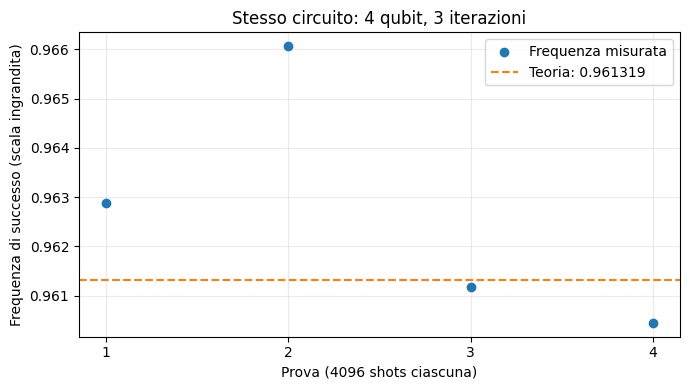

In [ ]:
# Un solo circuito: cambiamo soltanto il campione di misure.
trial_n = 4
trial_k = 3
trial_target = "0001"
trial_shots = 4096
trial_seeds = [RANDOM_SEED + i for i in range(4)]

trial_backend = make_ideal_backend()
trial_circuit = build_grover_circuit(trial_n, [trial_target], trial_k)
trial_compiled = transpile(trial_circuit, trial_backend,
                           optimization_level=IDEAL_OPTIMIZATION_LEVEL,
                           seed_transpiler=RANDOM_SEED)
trial_theory = theoretical_success_probability(2 ** trial_n, 1, trial_k)

trial_rows = []
for trial, seed in enumerate(trial_seeds, start=1):
    counts = trial_backend.run(trial_compiled, shots=trial_shots,
                               seed_simulator=seed).result().get_counts()
    successes = counts.get(trial_target, 0)
    frequency = successes / trial_shots
    trial_rows.append({
        "Prova": trial, "Seed": seed, "Shots": trial_shots, "Successi": successes,
        "Teoria": trial_theory, "Frequenza": frequency,
        "Scarto": frequency - trial_theory,
    })

repeated_trials_df = pd.DataFrame(trial_rows)
display(repeated_trials_df.round(6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(repeated_trials_df["Prova"], repeated_trials_df["Frequenza"],
           label="Frequenza misurata", zorder=3)
ax.axhline(trial_theory, color="tab:orange", linestyle="--",
           label=f"Teoria: {trial_theory:.6f}")
ax.set(xticks=repeated_trials_df["Prova"], xlabel="Prova (4096 shots ciascuna)",
       ylabel="Frequenza di successo (scala ingrandita)",
       title="Stesso circuito: 4 qubit, 3 iterazioni")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## 10. Simulazione con rumore depolarizzante
Il canale Aer su d dimensioni è $\mathcal E(\rho)=(1-p)\rho+pI/d$ per stati normalizzati.
Qui p1 e p2 sono **parametri del canale**, non direttamente infedeltà media o probabilità
di un errore Pauli non identità. Per questa API limitiamo i parametri all'intervallo [0,1].
Applichiamo p1 dopo ogni `u` (un qubit) e p2 dopo ogni `cx` (due qubit).
Il readout opzionale r è simmetrico e indipendente per qubit: matrice `[[1-r,r],[r,1-r]]`.

Serie principale: **p2 = 0, 0.001, 0.005, 0.01, 0.02; p1 = p2/10; r = 0**.
Questa è una famiglia di modelli sintetici, non una calibrazione hardware.
Confrontiamo n=3,4,5,6 al k ottimo ideale e, per n=6, tutti i k=0,...,8.
Per coppie (n,k) comuni manteniamo bitstring, 4096 shots, seed, base e ottimizzazione
identici alla serie ideale. Il seed comune non garantisce counts identici tra metodi diversi.
La compilazione avviene sullo stesso backend ideale **prima** di collegare il rumore,
così il NoiseModel non modifica il circuito confrontato. Verifichiamo le porte effettive.

Usiamo `density_matrix` per evolvere esattamente il canale e poi campionare le misure.
Salviamo anche `expected_noisy_probability`, ottenuta dalle probabilità prima della misura
e dalla matrice di readout. Serve a separare gli effetti fisici del modello dal campionamento.
Il tempo include `run`, `result` e il salvataggio diagnostico delle probabilità; esclude
compilazione e analisi. È tempo di simulazione classica lato Python, non durata su QPU.

Riferimenti Aer: [depolarizing_error](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.depolarizing_error.html),
[ReadoutError](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.ReadoutError.html).

In [14]:
def _noise_parameter(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise ValueError(f"{name} deve essere un numero reale in [0,1].")
    if not np.isfinite(value) or not 0 <= value <= 1:
        raise ValueError(f"{name} deve essere finito e in [0,1].")
    return float(value)


def create_depolarizing_noise_model(p1, p2, readout_error=None):
    """Rumore su u e cx; readout simmetrico opzionale su tutti i qubit."""
    p1 = _noise_parameter(p1, "p1")
    p2 = _noise_parameter(p2, "p2")
    r = 0.0 if readout_error is None else _noise_parameter(readout_error, "readout_error")
    model = NoiseModel(basis_gates=list(IDEAL_BASIS_GATES))
    if p1:
        model.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["u"])
    if p2:
        model.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    if r:
        model.add_all_qubit_readout_error(ReadoutError([[1-r, r], [r, 1-r]]))
    return model


def _apply_symmetric_readout(probabilities, n, r):
    """Trasforma le probabilità con errori classici indipendenti sui bit."""
    values = np.asarray(probabilities, dtype=float).copy()
    indices = np.arange(2 ** n)
    for q in range(n):
        values = (1-r) * values + r * values[indices ^ (1 << q)]
    return values


def run_noisy_experiment(n_qubits, marked_states, iterations, shots, seed,
                         p1, p2, readout_error=None):
    """Interfaccia ideale estesa con i parametri del rumore; restituisce una riga."""
    model = create_depolarizing_noise_model(p1, p2, readout_error)
    r = 0.0 if readout_error is None else float(readout_error)
    for name, value, minimum in (("shots", shots, 1), ("seed", seed, 0)):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} deve essere un intero >= {minimum}.")
    circuit = build_grover_circuit(n_qubits, marked_states, iterations, True)
    compiled = transpile(circuit, make_ideal_backend(int(seed)),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=int(seed))
    gates = compiled.remove_final_measurements(inplace=False)
    gate_items = [item for item in gates.data if item.operation.name not in {"barrier", "reset", "measure"}]
    actual_basis = sorted({item.operation.name for item in gate_items})
    assert set(actual_basis) <= set(IDEAL_BASIS_GATES)
    assert all(item.operation.num_qubits == {"u": 1, "cx": 2}[item.operation.name] for item in gate_items)
    for gate, strength in (("u", p1), ("cx", p2)):
        if strength > 0 and gate in actual_basis:
            assert gate in model.noise_instructions
    # Snapshot prima delle misure: non è una porta e non entra nelle risorse.
    executed = gates.copy()
    executed.save_probabilities(label="pre_measurement_probabilities")
    executed.measure_all()
    backend = AerSimulator(method="density_matrix", noise_model=model,
                           seed_simulator=int(seed), max_parallel_threads=1)
    start = perf_counter()
    result = backend.run(executed, shots=int(shots), seed_simulator=int(seed)).result()
    execution_time = perf_counter() - start
    if not result.success:
        raise RuntimeError(f"Simulazione noisy fallita: {result.status}")
    counts = dict(result.get_counts())
    assert sum(counts.values()) == shots
    normalized = {key: value / shots for key, value in counts.items()}
    measured = success_probability(normalized, marked_states)
    pre_measurement = np.asarray(result.data(0)["pre_measurement_probabilities"])
    assert np.all(pre_measurement >= -ATOL)
    np.testing.assert_allclose(pre_measurement.sum(), 1, atol=ATOL, rtol=0)
    expected_distribution = _apply_symmetric_readout(pre_measurement, n_qubits, r)
    expected_success = float(sum(expected_distribution[int(w, 2)] for w in marked_states))
    return {
        "backend": backend.name, "mode": "noisy", "n": n_qubits, "N": 2 ** n_qubits,
        "M": len(marked_states), "marked_states": tuple(marked_states), "k": iterations,
        "shots": int(shots), "theoretical_probability": theoretical_success_probability(2 ** n_qubits, len(marked_states), iterations),
        "measured_success_probability": measured, "success_probability": measured,
        "execution_time": execution_time,
        "depth": gates.depth(filter_function=lambda item: item.operation.name not in {"barrier", "reset", "measure"}),
        "total_gate_count": len(gate_items),
        "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in gate_items),
        "standard_error": float(np.sqrt(measured * (1-measured) / shots)),
        "seed": int(seed), "seed_transpiler": int(seed), "optimization_level": IDEAL_OPTIMIZATION_LEVEL,
        "basis_gates": IDEAL_BASIS_GATES, "counts": counts, "normalized_counts": normalized,
        "qiskit_version": LIBRARY_VERSIONS["qiskit"], "qiskit_aer_version": LIBRARY_VERSIONS["qiskit-aer"],
        "p1": float(p1), "p2": float(p2), "readout_error": r,
        "expected_noisy_probability": expected_success, "actual_basis_gates": ",".join(actual_basis),
        "simulation_method": "density_matrix", "experiment_group": "noise_scan",
    }


# Test analitici del canale e del readout, indipendenti da Grover.
assert create_depolarizing_noise_model(0, 0).is_ideal()
for bad in (-0.1, 1.1, float("nan"), True, "0.01"):
    for arguments in ((bad, 0, None), (0, bad, None), (0, 0, bad)):
        try:
            create_depolarizing_noise_model(*arguments)
        except ValueError:
            pass
        else:
            raise AssertionError("Parametro di rumore non valido accettato.")
probe = QuantumCircuit(1)
probe.u(np.pi, 0, np.pi, 0)  # |0> -> |1>, poi depolarizzazione p=0.2.
probe.save_probabilities()
probe_backend = AerSimulator(method="density_matrix", noise_model=create_depolarizing_noise_model(.2, 0),
                             max_parallel_threads=1)
probe_result = probe_backend.run(probe, shots=1).result()
np.testing.assert_allclose(probe_result.data(0)["probabilities"], [.1, .9], atol=ATOL, rtol=0)
np.testing.assert_allclose(_apply_symmetric_readout([.1, .9], 1, .1), [.18, .82], atol=ATOL, rtol=0)
# Readout r=1 deve invertire deterministicamente |0> in '1'.
readout_probe = QuantumCircuit(1, 1)
readout_probe.measure(0, 0)
readout_backend = AerSimulator(noise_model=create_depolarizing_noise_model(0, 0, 1), max_parallel_threads=1)
assert readout_backend.run(readout_probe, shots=32, seed_simulator=42).result().get_counts() == {"1": 32}
print("Test analitici del rumore e del readout superati.")
# Test analitico separato del canale a due qubit su CX.
two_qubit_probe = QuantumCircuit(2)
two_qubit_probe.u(np.pi, 0, np.pi, 0)
two_qubit_probe.cx(0, 1)
two_qubit_probe.save_probabilities()
two_qubit_backend = AerSimulator(method="density_matrix",
    noise_model=create_depolarizing_noise_model(0, .2), max_parallel_threads=1)
two_qubit_result = two_qubit_backend.run(two_qubit_probe, shots=1).result()
np.testing.assert_allclose(two_qubit_result.data(0)["probabilities"],
                           [.05, .05, .05, .85], atol=ATOL, rtol=0)

Test analitici del rumore e del readout superati.


In [15]:
# Conserva il batch ideale corrente; una riesecuzione non duplica il batch noisy.
ideal_results_df = results_df.loc[results_df["mode"] == "ideal_shots"].copy()
for column in ("p1", "p2", "readout_error"):
    ideal_results_df[column] = 0.0
ideal_results_df["success_probability"] = ideal_results_df.measured_success_probability
ideal_results_df["expected_noisy_probability"] = ideal_results_df.theoretical_probability
ideal_results_df["simulation_method"] = "statevector"
ideal_results_df["experiment_group"] = "ideal_scan"
ideal_basis = []
for row in ideal_results_df.itertuples():
    compiled = transpile(build_grover_circuit(int(row.n), row.marked_states, int(row.k), False),
                         make_ideal_backend(int(row.seed)),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=int(row.seed))
    ideal_basis.append(",".join(sorted({item.operation.name for item in compiled.data})))
ideal_results_df["actual_basis_gates"] = ideal_basis
ideal_results_df = ideal_results_df.astype(RESULT_DTYPES)

NOISE_P2_VALUES = (0.0, 0.001, 0.005, 0.01, 0.02)
noisy_rows = []
for n in (3, 4, 5, 6):
    ks = range(9) if n == 6 else [optimal_grover_iterations(2 ** n, 1)]
    for k in ks:
        for p2 in NOISE_P2_VALUES:
            noisy_rows.append(run_noisy_experiment(n, (format(1, f"0{n}b"),), k,
                              SHOTS_DEFAULT, RANDOM_SEED + 100 * n + k, p2 / 10, p2))
noisy_results_df = pd.DataFrame(noisy_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([ideal_results_df, noisy_results_df], ignore_index=True).astype(RESULT_DTYPES)
assert len(ideal_results_df) == 24 and len(noisy_results_df) == 60
assert not noisy_results_df.duplicated(["n", "k", "p1", "p2", "readout_error"]).any()
assert (noisy_results_df.shots == SHOTS_DEFAULT).all()
assert (noisy_results_df.execution_time >= 0).all()
assert (noisy_results_df.total_gate_count >= noisy_results_df.two_qubit_gate_count).all()
assert noisy_results_df.success_probability.between(0, 1).all()
assert set(noisy_results_df.actual_basis_gates) <= {"u", "cx,u"}
for row in noisy_results_df.itertuples():
    matching = ideal_results_df[(ideal_results_df.n == row.n) & (ideal_results_df.k == row.k)]
    if not matching.empty:
        baseline = matching.iloc[0]
        for field in ("marked_states", "shots", "seed", "seed_transpiler", "basis_gates", "optimization_level",
                      "depth", "total_gate_count", "two_qubit_gate_count", "actual_basis_gates"):
            assert getattr(row, field) == baseline[field], f"Confronto non equivalente: {field}"
zero_noise = noisy_results_df[noisy_results_df.p2 == 0]
np.testing.assert_allclose(zero_noise.expected_noisy_probability.to_numpy(dtype=float),
                           zero_noise.theoretical_probability.to_numpy(dtype=float), atol=ATOL, rtol=0)
noisy_threshold = np.sqrt(np.log(2 * len(noisy_results_df) / 1e-6) / (2 * SHOTS_DEFAULT))
assert ((noisy_results_df.success_probability - noisy_results_df.expected_noisy_probability).abs()
        <= noisy_threshold).all()
optimum_noise_df = noisy_results_df[
    noisy_results_df.apply(lambda row: row.k == optimal_grover_iterations(int(row.N), int(row.M)), axis=1)
].copy()
for n, group in optimum_noise_df.groupby("n"):
    group = group.sort_values("p2")
    # Ai k ottimi verifichiamo il calo esatto del modello, senza imporlo ai counts.
    assert np.all(np.diff(group.expected_noisy_probability.to_numpy(dtype=float)) <= ATOL)
    assert group.iloc[-1].expected_noisy_probability < group.iloc[0].expected_noisy_probability
display(optimum_noise_df[["n", "k", "p1", "p2", "success_probability", "expected_noisy_probability",
                          "standard_error", "depth", "total_gate_count", "two_qubit_gate_count", "actual_basis_gates"]])
print(f"Batch conservati: {len(ideal_results_df)} ideali + {len(noisy_results_df)} noisy.")

,n,k,p1,p2,success_probability,expected_noisy_probability,standard_error,depth,total_gate_count,two_qubit_gate_count,actual_basis_gates
0,3,2,0.0,0.0,0.944092,0.945313,0.00359,45,63,24,"cx,u"
1,3,2,0.0001,0.001,0.926514,0.925366,0.004077,45,63,24,"cx,u"
2,3,2,0.0005,0.005,0.858887,0.850192,0.00544,45,63,24,"cx,u"
3,3,2,0.001,0.01,0.776367,0.765828,0.006511,45,63,24,"cx,u"
4,3,2,0.002,0.02,0.633545,0.62476,0.007529,45,63,24,"cx,u"
5,4,3,0.0,0.0,0.959473,0.961319,0.003081,157,178,84,"cx,u"
6,4,3,0.0001,0.001,0.890869,0.89389,0.004872,157,178,84,"cx,u"
7,4,3,0.0005,0.005,0.671875,0.671225,0.007336,157,178,84,"cx,u"
8,4,3,0.001,0.01,0.459961,0.474984,0.007787,157,178,84,"cx,u"
9,4,3,0.002,0.02,0.246094,0.252276,0.00673,157,178,84,"cx,u"


Batch conservati: 24 ideali + 60 noisy.


### 10.1 Profondità, decomposizione e interpretazione
Le rotazioni di Grover amplificano idealmente le soluzioni fino al primo massimo.
Più iterazioni comportano anche più porte: i canali depolarizzanti ripetuti degradano
la coerenza necessaria all'interferenza. L'ottimo noisy può quindi anticipare quello ideale.
Le MCX presenti in oracle e diffusore non appartengono alla base `u,cx`: il transpiler
le decompone in porte elementari. Il numero di CX e la profondità possono crescere molto
più del numero di interrogazioni all'oracolo. Qui assegniamo ai CX un parametro dieci volte
quello delle porte singole; nei dispositivi NISQ anche connettività, durata e calibrazione
delle porte entangling incidono sul costo, ma questo modello non le rappresenta.

Restano distinte: **query complexity** ideale $O(\sqrt{N/M})$, profondità dopo compilazione,
tempo del simulatore classico e prestazione su hardware NISQ. Nessuna misura qui stabilisce
un vantaggio temporale quantistico o predice una specifica QPU.

I grafici mostrano ±1 errore standard binomiale. La linea esatta del modello aiuta a leggere
i piccoli scarti. L'argmax empirico è selezionato su una griglia finita e può fluttuare;
non assegniamo a k una barra binomiale. Segnaliamo anche aumenti locali con il rumore:
vicino a un minimo di overshooting, mescolare verso la distribuzione uniforme può aumentare
il successo rispetto a un circuito ideale già sfavorevole. Non è un miglioramento generale.

,p1,p2,k,exact_best_k,success_probability,standard_error
45,0.0,0.0,6,6,0.996094,0.000975
41,0.0001,0.001,5,5,0.466553,0.007795
27,0.0005,0.005,2,2,0.084961,0.004357
23,0.001,0.01,1,1,0.031494,0.002729
44,0.002,0.02,5,1,0.018066,0.002081


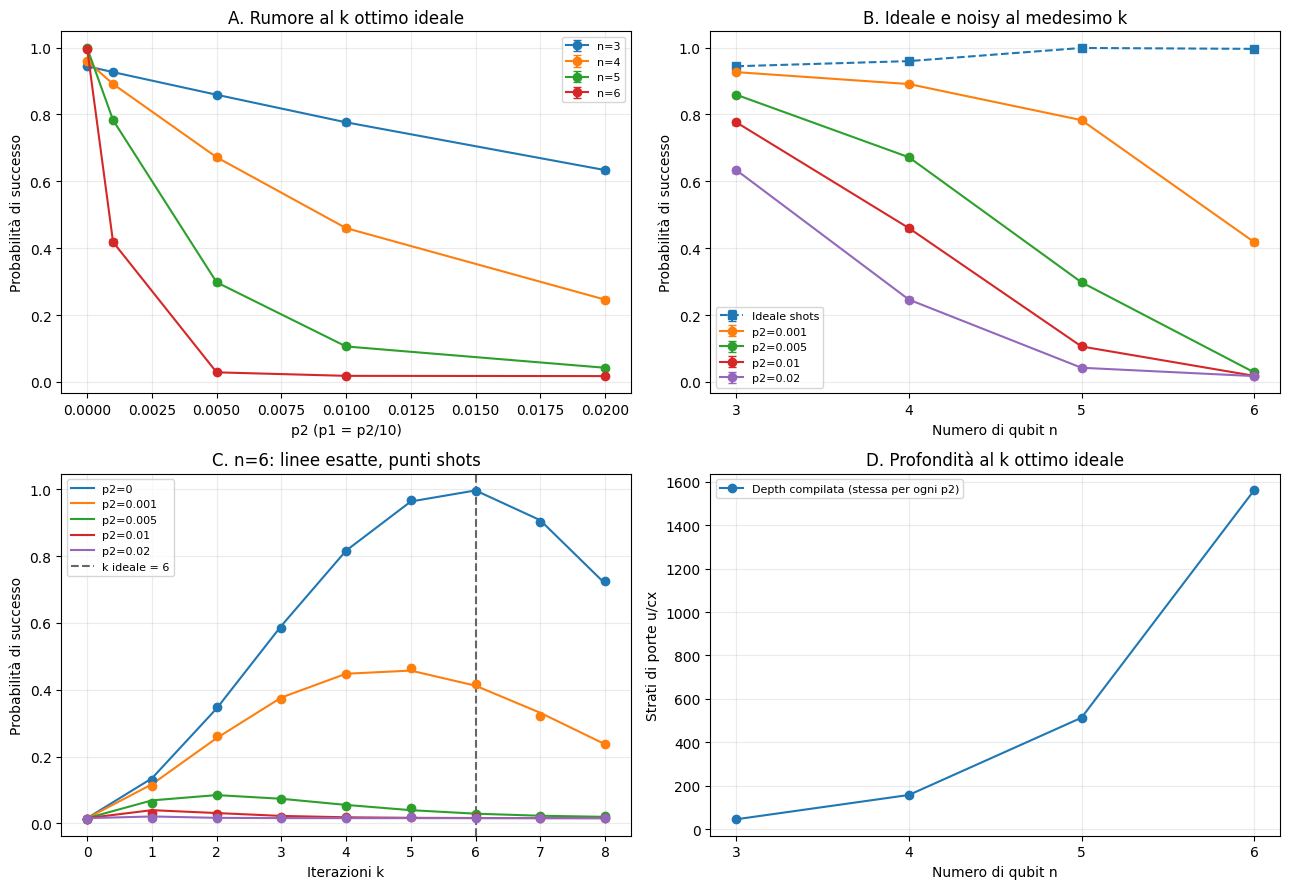

Ottimo ideale n=6: 6
p2=0: miglior k misurato=6, miglior k del modello=6
p2=0.001: miglior k misurato=5, miglior k del modello=5
p2=0.005: miglior k misurato=2, miglior k del modello=2
p2=0.01: miglior k misurato=1, miglior k del modello=1
p2=0.02: miglior k misurato=5, miglior k del modello=1
Aumenti locali misurati con p2 (non nascosti): 1


,n,k,p2_before,p2_after,measured_increase,model_change
0,6,8,0.01,0.02,0.000244,-0.000088


,k,depth,total_gate_count,two_qubit_gate_count,theoretical_probability,expected_noisy_probability,success_probability
18,0,1,6,0,0.015625,0.015625,0.01416
23,1,261,364,168,0.134827,0.039587,0.031494
28,2,521,722,336,0.343895,0.03094,0.029541
33,3,781,1080,504,0.59138,0.022353,0.017822
38,4,1041,1438,672,0.816377,0.01826,0.020508
43,5,1301,1796,840,0.963515,0.016655,0.018555
48,6,1561,2154,1008,0.996586,0.01605,0.018066
53,7,1821,2512,1176,0.907449,0.015813,0.014893
58,8,2081,2870,1344,0.718042,0.015713,0.01709


In [16]:
sweep = noisy_results_df[noisy_results_df.n == 6].sort_values(["p2", "k"])
best_noisy_df = (sweep.sort_values(["p2", "success_probability", "k"], ascending=[True, False, True])
                .groupby("p2").head(1).sort_values("p2").copy())
best_exact = (sweep.sort_values(["p2", "expected_noisy_probability", "k"], ascending=[True, False, True])
              .groupby("p2").head(1).set_index("p2")["k"])
best_noisy_df["exact_best_k"] = best_noisy_df.p2.map(best_exact)
display(best_noisy_df[["p1", "p2", "k", "exact_best_k", "success_probability", "standard_error"]])
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for n, group in optimum_noise_df.groupby("n"):
    group = group.sort_values("p2")
    axes[0, 0].errorbar(group.p2.to_numpy(dtype=float), group.success_probability.to_numpy(dtype=float),
                        yerr=group.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3, label=f"n={n}")
axes[0, 0].set(title="A. Rumore al k ottimo ideale", xlabel="p2 (p1 = p2/10)", ylabel="Probabilità di successo")
ideal_optima = ideal_results_df[ideal_results_df.apply(
    lambda row: row.n >= 3 and row.k == optimal_grover_iterations(int(row.N), 1), axis=1)].sort_values("n")
axes[0, 1].errorbar(ideal_optima.n.to_numpy(dtype=float), ideal_optima.success_probability.to_numpy(dtype=float),
                    yerr=ideal_optima.standard_error.to_numpy(dtype=float), fmt="s--", capsize=3, label="Ideale shots")
for p2, group in optimum_noise_df[optimum_noise_df.p2 > 0].groupby("p2"):
    group = group.sort_values("n")
    axes[0, 1].errorbar(group.n.to_numpy(dtype=float), group.success_probability.to_numpy(dtype=float),
                        yerr=group.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3, label=f"p2={p2:g}")
axes[0, 1].set(title="B. Ideale e noisy al medesimo k", xlabel="Numero di qubit n", ylabel="Probabilità di successo", xticks=[3,4,5,6])
for p2, group in sweep.groupby("p2"):
    line, = axes[1, 0].plot(group.k, group.expected_noisy_probability, label=f"p2={p2:g}")
    axes[1, 0].errorbar(group.k.to_numpy(dtype=float), group.success_probability.to_numpy(dtype=float),
                        yerr=group.standard_error.to_numpy(dtype=float), fmt="o", capsize=2, color=line.get_color())
axes[1, 0].axvline(optimal_grover_iterations(64, 1), color="0.4", linestyle="--", label="k ideale = 6")
axes[1, 0].set(title="C. n=6: linee esatte, punti shots", xlabel="Iterazioni k", ylabel="Probabilità di successo", xticks=range(9))
resource_rows = optimum_noise_df[optimum_noise_df.p2 == 0].sort_values("n")
axes[1, 1].plot(resource_rows.n, resource_rows.depth, "o-", label="Depth compilata (stessa per ogni p2)")
axes[1, 1].set(title="D. Profondità al k ottimo ideale", xlabel="Numero di qubit n", ylabel="Strati di porte u/cx", xticks=[3,4,5,6])
for ax in axes.flat:
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

print("Ottimo ideale n=6:", optimal_grover_iterations(64, 1))
for row in best_noisy_df.itertuples():
    print(f"p2={row.p2:g}: miglior k misurato={row.k}, miglior k del modello={row.exact_best_k}")
anomalies = []
for (n, k), group in noisy_results_df.groupby(["n", "k"]):
    ordered = group.sort_values("p2")
    for before, after in zip(list(ordered.itertuples())[:-1], list(ordered.itertuples())[1:]):
        if after.success_probability > before.success_probability:
            anomalies.append({"n": n, "k": k, "p2_before": before.p2, "p2_after": after.p2,
                              "measured_increase": after.success_probability-before.success_probability,
                              "model_change": after.expected_noisy_probability-before.expected_noisy_probability})
print("Aumenti locali misurati con p2 (non nascosti):", len(anomalies))
if anomalies:
    display(pd.DataFrame(anomalies))
display(sweep[sweep.p2 == .01][["k", "depth", "total_gate_count", "two_qubit_gate_count",
                               "theoretical_probability", "expected_noisy_probability", "success_probability"]])

### 10.2 Risultati osservati e comportamento controintuitivo
Al k ideale, la probabilità esatta del modello diminuisce a ogni livello di rumore per tutti gli n studiati.
Per n=6, k=6, passa da circa 0.9966 senza rumore a 0.4122 con p2=0.001 e 0.01563 con p2=0.02,
vicino al valore uniforme 1/64. La profondità della compilazione aiuta a spiegare questa sensibilità.

Nella griglia k=0,...,8, per p2=0, 0.001, 0.005 e 0.01 i massimi misurati e quelli del modello
coincidono rispettivamente a k=6, 5, 2 e 1. Questo rende visibile il compromesso tra amplificazione
ideale e accumulo di rumore per le porte aggiuntive.

**Eccezione da non nascondere:** per p2=0.02 gli shots selezionano k=5 (0.01807), mentre
il modello ha il massimo a k=1 (0.02071 atteso, 0.01538 misurato). A k=5 il modello vale 0.01564.
Le curve sono quasi piatte vicino alla distribuzione uniforme e le frequenze fluttuano:
il massimo empirico di una sola serie non identifica con affidabilità quello del modello.
Servirebbero repliche indipendenti o più shots per valutare la stabilità della selezione.
La tabella degli aumenti locali riporta ogni incremento misurato, anche quando la previsione del
modello diminuisce; non imponiamo la monotonia ai campioni né eliminiamo le righe sfavorevoli.


## 11. Scaling ideale con la dimensione dello spazio di ricerca
Eseguiamo un nuovo batch **ideale**, separato dal noisy, con n=2,...,7, M=1 e 4096 shots.
Ogni circuito usa il k ottimo intero vicino al primo massimo e lo stato marcato `00...001`.
Manteniamo base `u,cx`, ottimizzazione livello 1 e seed deterministico. Tutte le esecuzioni
sono registrate nel DataFrame generale con `experiment_group="scaling"`.

La stima $(\pi/4)\sqrt N$ riguarda le interrogazioni all'oracolo; le risorse circuitali
includono invece la decomposizione di oracle e diffusore. Il tempo riportato è una singola
misura classica `run`–`result` di Aer, senza compilazione: overhead, scheduling e implementazione
del simulatore possono produrre irregolarità. Non è tempo quantistico né una misura affidabile
di scaling temporale asintotico. Non assegnamo barre d'errore ai tempi senza repliche.

c:\Users\pier2\Documents\GitHub\QuantumComputing\.venv\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
c:\Users\pier2\Documents\GitHub\QuantumComputing\.venv\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
c:\Users\pier2\Documents\GitHub\QuantumComputing\.venv\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the back

,n,N,k_opt,depth,total_gate_count,two_qubit_gate_count,execution_time,theoretical_probability,success_probability,standard_error
0,2,4,1,5,8,2,0.008438,1.0,1.0,0.0
1,3,8,2,45,63,24,0.00455,0.945312,0.944092,0.00359
2,4,16,3,157,178,84,0.006995,0.961319,0.959473,0.003081
3,5,32,4,513,629,288,0.014365,0.999182,0.998779,0.000546
4,6,64,6,1561,2154,1008,0.026819,0.996586,0.996094,0.000975
5,7,128,8,3027,4471,1984,0.055571,0.99562,0.995605,0.001034


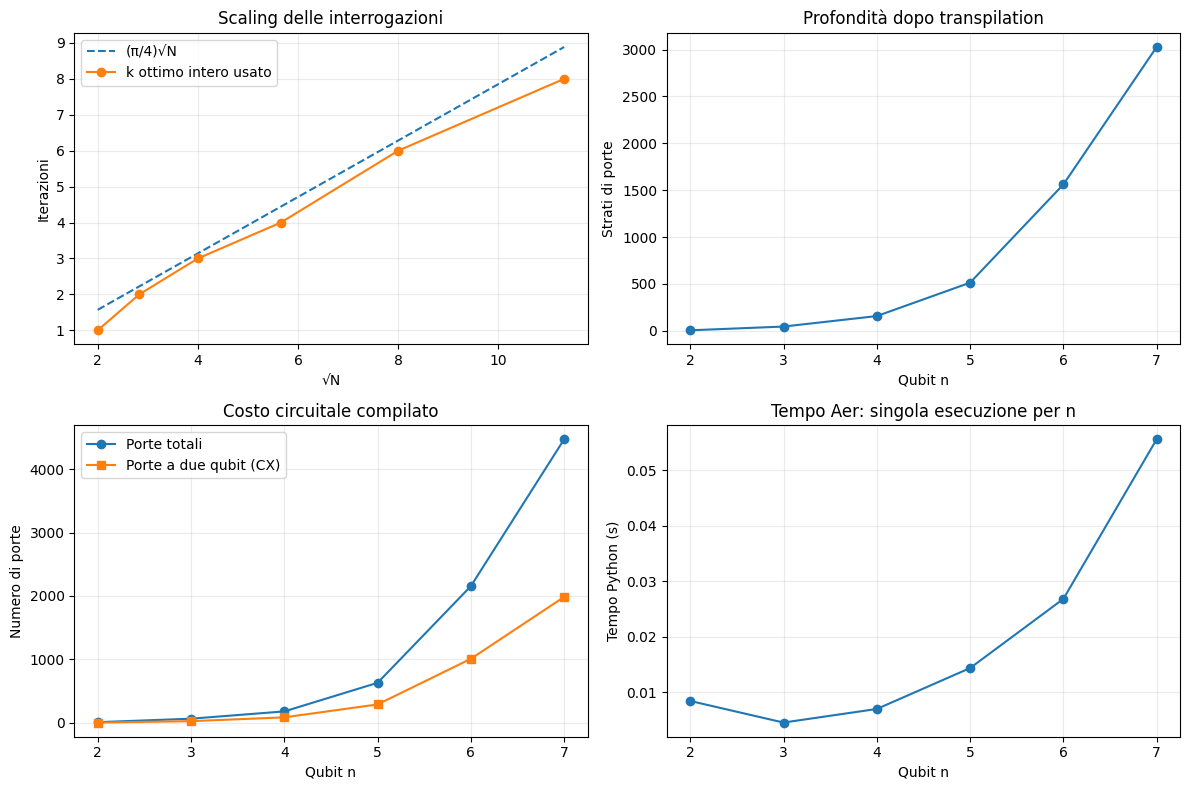

In [17]:
def run_tagged_ideal_experiment(n, marked, k, shots, seed, group):
    """Riusa l'esecuzione ideale e completa i metadati del DataFrame generale."""
    row = run_ideal_experiment(n, marked, k, shots, seed)
    compiled = transpile(build_grover_circuit(n, marked, k, False), make_ideal_backend(seed),
                         basis_gates=list(IDEAL_BASIS_GATES),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=seed)
    row.update(p1=0.0, p2=0.0, readout_error=0.0,
               success_probability=row["measured_success_probability"],
               expected_noisy_probability=row["theoretical_probability"],
               actual_basis_gates=",".join(sorted({item.operation.name for item in compiled.data})),
               simulation_method="statevector", experiment_group=group,
               theta=grover_theta(2 ** n, len(marked)),
               k_opt=optimal_grover_iterations(2 ** n, len(marked)))
    return row


# Estende lo schema anche per i batch precedenti, senza cambiare i loro risultati.
RESULT_DTYPES.update({"theta": "Float64", "k_opt": "Int64"})
results_df["theta"] = [grover_theta(int(N), int(M)) for N, M in zip(results_df.N, results_df.M)]
results_df["k_opt"] = [optimal_grover_iterations(int(N), int(M)) for N, M in zip(results_df.N, results_df.M)]
results_df = results_df.astype(RESULT_DTYPES)
scaling_rows = []
for n in range(2, 8):
    k = optimal_grover_iterations(2 ** n, 1)
    scaling_rows.append(run_tagged_ideal_experiment(n, (format(1, f"0{n}b"),), k,
                        SHOTS_DEFAULT, RANDOM_SEED + 100 * n + k, "scaling"))
scaling_df = pd.DataFrame(scaling_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df.experiment_group != "scaling"], scaling_df],
                       ignore_index=True).astype(RESULT_DTYPES)
assert len(scaling_df) == 6 and set(scaling_df.n) == set(range(2, 8))
assert np.all(np.diff(scaling_df.k_opt.to_numpy(dtype=int)) >= 0)
assert (scaling_df.k == scaling_df.k_opt).all()
scaling_summary_df = scaling_df[["n", "N", "k_opt", "depth", "total_gate_count",
    "two_qubit_gate_count", "execution_time", "theoretical_probability", "success_probability", "standard_error"]]
display(scaling_summary_df)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
root_N = np.sqrt(scaling_df.N.to_numpy(dtype=float))
axes[0, 0].plot(root_N, np.pi/4 * root_N, "--", label="(π/4)√N")
axes[0, 0].plot(root_N, scaling_df.k_opt, "o-", label="k ottimo intero usato")
axes[0, 0].set(xlabel="√N", ylabel="Iterazioni", title="Scaling delle interrogazioni")
axes[0, 1].plot(scaling_df.n, scaling_df.depth, "o-")
axes[0, 1].set(xlabel="Qubit n", ylabel="Strati di porte", title="Profondità dopo transpilation")
axes[1, 0].plot(scaling_df.n, scaling_df.total_gate_count, "o-", label="Porte totali")
axes[1, 0].plot(scaling_df.n, scaling_df.two_qubit_gate_count, "s-", label="Porte a due qubit (CX)")
axes[1, 0].set(xlabel="Qubit n", ylabel="Numero di porte", title="Costo circuitale compilato")
axes[1, 1].plot(scaling_df.n, scaling_df.execution_time, "o-")
axes[1, 1].set(xlabel="Qubit n", ylabel="Tempo Python (s)", title="Tempo Aer: singola esecuzione per n")
for ax in axes.flat:
    ax.grid(alpha=.25)
for ax in (axes[0, 0], axes[1, 0]):
    ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

## 12. Più soluzioni: esperimento ideale a n=5, N=32
Generiamo insiemi annidati e riproducibili con indici $(1+7i)\bmod 2^n$, i=0,...,M-1.
Poiché 7 è coprimo con $2^n$, gli indici non si ripetono prima di aver visitato tutta la base.
Per M=1,2,4,8 eseguiamo k=0,...,8 con 4096 shots per circuito. Il successo è la somma
delle frequenze di **qualsiasi** stato marcato, calcolata dall'helper condiviso.

Per $0<M<N$, $|G\rangle=M^{-1/2}\sum_{w\in W}|w\rangle$ e
$|B\rangle=(N-M)^{-1/2}\sum_{x\notin W}|x\rangle$ restano una base ortonormale
del sottospazio bidimensionale accessibile. Con $\theta=\arcsin\sqrt{M/N}$,
$$|\psi_k\rangle=\cos((2k+1)\theta)|B\rangle+\sin((2k+1)\theta)|G\rangle.$$
La simmetria preserva ampiezze uguali all'interno di ciascun gruppo. Gli assert confrontano
anche lo stato completo con questa formula, oltre alla probabilità totale.

Aumentando M cresce l'angolo di rotazione e il primo massimo richiede meno iterazioni.
La scelta intera può creare plateau in generale; per i quattro M scelti verifichiamo
la diminuzione stretta. La probabilità al k scelto non deve invece crescere monotonicamente
con M, perché l'angolo ottimo può cadere tra interi. Inoltre il nostro oracle marca gli stati
uno alla volta: ridurre le query non implica necessariamente ridurre il costo totale delle porte.

c:\Users\pier2\Documents\GitHub\QuantumComputing\.venv\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
c:\Users\pier2\Documents\GitHub\QuantumComputing\.venv\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
c:\Users\pier2\Documents\GitHub\QuantumComputing\.venv\Lib\site-packages\qiskit\transpiler\preset_passmanagers\generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the back

,M,theta,k_opt,theoretical_probability,measured_probability,standard_error
4,1,0.177711,4,0.999182,0.999512,0.000345
12,2,0.25268,3,0.961319,0.964844,0.002878
20,4,0.361367,2,0.945312,0.942871,0.003626
28,8,0.523599,1,1.0,1.0,0.0


Nuove esecuzioni ideali: 42; errore massimo da teoria: 0.015625


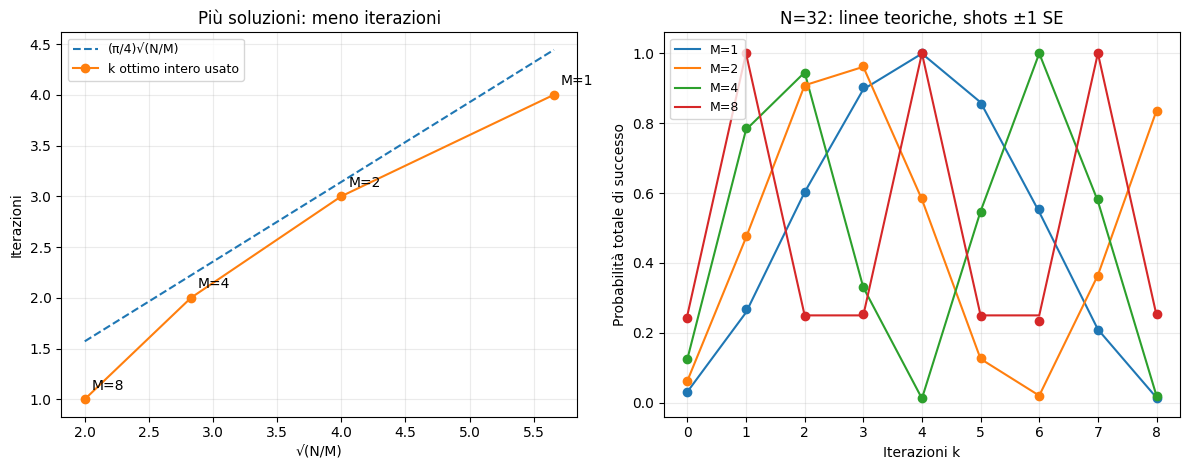

In [18]:
def deterministic_marked_states(n_qubits, M):
    """Insiemi annidati senza duplicati, nell'ordine Qiskit q[n-1]...q[0]."""
    if isinstance(n_qubits, bool) or not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("n_qubits deve essere un intero positivo.")
    if isinstance(M, bool) or not isinstance(M, int) or not 1 <= M <= 2 ** n_qubits:
        raise ValueError("M deve essere un intero tra 1 e 2**n_qubits.")
    states = tuple(format((1 + 7*i) % (2 ** n_qubits), f"0{n_qubits}b") for i in range(M))
    validate_problem(n_qubits, states)
    return states


MULTI_N = 5
M_VALUES = (1, 2, 4, 8)
multi_rows = []
for M in M_VALUES:
    marked = deterministic_marked_states(MULTI_N, M)
    assert len(marked) == len(set(marked)) == M
    assert marked == deterministic_marked_states(MULTI_N, M)
    theta = grover_theta(32, M)
    np.testing.assert_allclose(np.sin(theta)**2, M/32, atol=ATOL, rtol=0)
    for k in range(9):
        state = Statevector.from_instruction(build_grover_circuit(MULTI_N, marked, k, False))
        expected = np.full(32, np.cos((2*k+1)*theta) / np.sqrt(32-M), dtype=complex)
        expected[[int(w, 2) for w in marked]] = np.sin((2*k+1)*theta) / np.sqrt(M)
        np.testing.assert_allclose(state.data, expected, atol=ATOL, rtol=0)
        np.testing.assert_allclose(success_probability(state.probabilities_dict(), marked),
                                   theoretical_success_probability(32, M, k), atol=ATOL, rtol=0)
        multi_rows.append(run_tagged_ideal_experiment(MULTI_N, marked, k, SHOTS_DEFAULT,
                          RANDOM_SEED + 10000 + 100*M + k, "multiple_solutions"))
multiple_solutions_df = pd.DataFrame(multi_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df.experiment_group != "multiple_solutions"], multiple_solutions_df],
                       ignore_index=True).astype(RESULT_DTYPES)
multiple_summary_df = multiple_solutions_df[multiple_solutions_df.k == multiple_solutions_df.k_opt][
    ["M", "theta", "k_opt", "theoretical_probability", "success_probability", "standard_error"]
].sort_values("M").rename(columns={"success_probability": "measured_probability"})
assert len(multiple_summary_df) == len(M_VALUES)
assert np.all(np.diff(multiple_summary_df.k_opt.to_numpy(dtype=int)) < 0)
assert multiple_summary_df.k_opt.to_list() == [4, 3, 2, 1]
np.testing.assert_allclose(theoretical_success_probability(32, 8, 1), 1, atol=ATOL, rtol=0)
for M in M_VALUES:
    np.testing.assert_allclose(theoretical_success_probability(32, M, 0), M/32, atol=ATOL, rtol=0)
assert len(deterministic_marked_states(5, 32)) == 32
assert set(deterministic_marked_states(5, 4)) <= set(deterministic_marked_states(5, 8))
for args in ((0, 1), (5, 0), (5, 33), (5, True)):
    try:
        deterministic_marked_states(*args)
    except ValueError:
        pass
    else:
        raise AssertionError("Input non valido accettato.")
display(multiple_summary_df)

new_ideal = pd.concat([scaling_df, multiple_solutions_df], ignore_index=True)
threshold = np.sqrt(np.log(2 * len(new_ideal) / 1e-6) / (2*SHOTS_DEFAULT))
assert ((new_ideal.success_probability - new_ideal.theoretical_probability).abs() <= threshold).all()
assert (new_ideal["mode"] == "ideal_shots").all() and (new_ideal.p2 == 0).all()
assert len(results_df) == 126
assert len(results_df[results_df["mode"] == "noisy"]) == 60
assert not results_df.duplicated(["experiment_group", "n", "M", "k", "p2", "seed"]).any()
print(f"Nuove esecuzioni ideali: {len(new_ideal)}; errore massimo da teoria: "
      f"{(new_ideal.success_probability-new_ideal.theoretical_probability).abs().max():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
x_values = np.sqrt(32 / multiple_summary_df.M.to_numpy(dtype=float))
order = np.argsort(x_values)
axes[0].plot(x_values[order], np.pi/4 * x_values[order], "--", label="(π/4)√(N/M)")
axes[0].plot(x_values, multiple_summary_df.k_opt, "o-", label="k ottimo intero usato")
for x, row in zip(x_values, multiple_summary_df.itertuples()):
    axes[0].annotate(f"M={row.M}", (x, row.k_opt), xytext=(5, 7), textcoords="offset points")
axes[0].set(xlabel="√(N/M)", ylabel="Iterazioni", title="Più soluzioni: meno iterazioni")
for M, group in multiple_solutions_df.groupby("M"):
    group = group.sort_values("k")
    line, = axes[1].plot(group.k, group.theoretical_probability, label=f"M={M}")
    axes[1].errorbar(group.k.to_numpy(dtype=float), group.success_probability.to_numpy(dtype=float),
                     yerr=group.standard_error.to_numpy(dtype=float), fmt="o", capsize=2, color=line.get_color())
axes[1].set(xlabel="Iterazioni k", ylabel="Probabilità totale di successo",
            title="N=32: linee teoriche, shots ±1 SE", xticks=range(9), ylim=(-.04, 1.06))
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend(fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

## 13. IBM Quantum hardware reale — opzionale
Questa sezione richiede `qiskit-ibm-runtime` e un account IBM Quantum già configurato localmente,
con accesso a un'istanza e quota disponibile. Non contiene token, non salva credenziali e non stampa
account o messaggi grezzi delle eccezioni. L'invio dei job è disattivato per default.
Per usarla, installare Runtime nell'ambiente del kernel e configurare l'account esternamente,
quindi impostare `ENABLE_IBM_HARDWARE=True` e rieseguire solo questa sezione.

Verifica dell'ambiente durante questa modifica: **Qiskit 2.5.2; qiskit-ibm-runtime assente**.
Il percorso remoto non è stato validato con un account reale. Usiamo le API documentate
`QiskitRuntimeService()`, `SamplerV2(mode=backend)` e `transpile(..., backend=backend)`;
la configurazione verifica import e firma prima dell'uso e gestisce incompatibilità o accesso negato.
Un problema hardware lascia intatti gli esperimenti precedenti.

Fonti: [Runtime e account salvati](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/runtime-service),
[SamplerV2](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/sampler-v2),
[metriche dei job](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/runtime-job-v2).

La scoperta seleziona backend reali operativi con almeno 3 qubit. Quando nota, la coda deve essere
al più `MAX_PENDING_JOBS`; una coda ignota è ammessa ma ordinata dopo quelle note.
Ordiniamo per coda e poi errore mediano delle porte a due qubit nel target, se disponibile.
Quest'ultimo è un indicatore globale di calibrazione, non la qualità garantita del layout selezionato.
Il nome del backend non è hardcodato. Data di calibrazione e dati mancanti sono mostrati esplicitamente.

In [19]:
from importlib.metadata import PackageNotFoundError
from datetime import datetime, timezone
import inspect
import hashlib

ENABLE_IBM_HARDWARE = False
HARDWARE_N_VALUES = (2, 3)
HARDWARE_SHOTS = 4096
MAX_PENDING_JOBS = 100
HARDWARE_RESULT_TIMEOUT = 60  # Un timeout non cancella un job già inviato.
HARDWARE_NOISE_P1 = 0.0001
HARDWARE_NOISE_P2 = 0.001
hardware_service = None
hardware_backend = None
hardware_backend_table = pd.DataFrame()
hardware_status = "non configurato"
try:
    hardware_runtime_version = version("qiskit-ibm-runtime")
except PackageNotFoundError:
    hardware_runtime_version = None
print("Qiskit:", version("qiskit"), "| IBM Runtime:", hardware_runtime_version or "non installato")

def hardware_notice(stage, error=None):
    # Non interpolare str(error): potrebbe includere dettagli di autenticazione.
    suffix = f" ({type(error).__name__})" if error is not None else ""
    print(f"Hardware: {stage}{suffix}. I risultati locali rimangono invariati.")

def hardware_backend_info(backend):
    status = backend.status()
    errors = []
    for instruction, qargs in backend.target.instructions:
        if instruction.num_qubits == 2 and qargs is not None:
            properties = backend.target[instruction.name].get(qargs)
            if properties is not None and properties.error is not None and np.isfinite(properties.error):
                errors.append(float(properties.error))
    calibration_date = None
    try:
        properties = backend.properties()
        if properties is not None and properties.last_update_date is not None:
            calibration_date = properties.last_update_date.isoformat()
    except Exception:
        pass
    edges = list(backend.coupling_map.get_edges()) if backend.coupling_map is not None else []
    return {"backend": backend.name, "num_qubits": backend.num_qubits,
            "operational": bool(status.operational), "pending_jobs": getattr(status, "pending_jobs", None),
            "median_two_qubit_error": float(np.median(errors)) if errors else None,
            "calibration_date": calibration_date,
            "basis_gates": sorted(backend.operation_names), "coupling_edge_count": len(edges),
            "coupling_sample": [list(edge) for edge in edges[:12]]}

if hardware_runtime_version is None:
    hardware_status = "dipendenza qiskit-ibm-runtime assente"
    hardware_notice(hardware_status)
else:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
        if "mode" not in inspect.signature(SamplerV2).parameters:
            raise RuntimeError("API SamplerV2 non compatibile")
        hardware_service = QiskitRuntimeService()  # Account preconfigurato, nessun token nel notebook.
        candidates = hardware_service.backends(simulator=False, operational=True,
                                               min_num_qubits=max(HARDWARE_N_VALUES))
        backend_objects, backend_rows = {}, []
        for candidate in candidates:
            try:
                info = hardware_backend_info(candidate)
                if not info["operational"] or info["num_qubits"] < max(HARDWARE_N_VALUES):
                    continue
                pending = info["pending_jobs"]
                if pending is not None and pending > MAX_PENDING_JOBS:
                    continue
                backend_objects[info["backend"]] = candidate
                backend_rows.append(info)
            except Exception as error:
                hardware_notice("metadati di un backend non disponibili", error)
        if backend_rows:
            hardware_backend_table = pd.DataFrame(backend_rows).sort_values(
                ["pending_jobs", "median_two_qubit_error", "backend"], na_position="last")
            display(hardware_backend_table)
            hardware_backend = backend_objects[hardware_backend_table.iloc[0]["backend"]]
            hardware_status = "backend disponibile"
            print("Backend selezionato:", hardware_backend.name)
        else:
            hardware_status = "nessun backend accessibile soddisfa i criteri"
            hardware_notice(hardware_status)
    except Exception as error:
        hardware_status = "accesso/API non disponibile: verificare account, istanza, rete e versione Runtime"
        hardware_notice(hardware_status, error)
if not ENABLE_IBM_HARDWARE:
    print("Invio job disattivato: ENABLE_IBM_HARDWARE=False.")

Qiskit: 2.5.2 | IBM Runtime: 0.49.0
Hardware: accesso/API non disponibile: verificare account, istanza, rete e versione Runtime (AccountNotFoundError). I risultati locali rimangono invariati.
Invio job disattivato: ENABLE_IBM_HARDWARE=False.


### 13.1 Esecuzione, confronti e misure di tempo
Per n=2,3 usiamo lo stesso problema logico `00...001`, k ottimo e shots in tutte le modalità.
I simulatori usano la base locale `u,cx`; il circuito hardware usa il target e il layout del backend.
Il confronto noisy è **sintetico** (p1=0.0001, p2=0.001, readout=0), non una previsione calibrata
del dispositivo. Le sue metriche vengono conservate separatamente. Non si simula il registro fisico
completo di un grande backend con Statevector. La mappa qubit→bit classici preserva l'interpretazione
delle stringhe anche dopo il layout; i counts Sampler vengono letti dal registro classico originale.

Profondità e porte escludono misure, barriere e reset. La profondità pre-transpilation contiene
anche porte multi-controllate astratte: il rapporto post/pre include decomposizione, routing e
ottimizzazione e non isola il solo costo della connettività. Registriamo porte effettive e layout.

Tempi distinti: `submission_seconds` misura la chiamata run; `client_total_seconds` include
sottomissione, attesa e restituzione solo se osservati nello stesso processo; `retrieval_seconds`
misura l'attesa di result. Dai timestamp server ricaviamo `server_pre_running_seconds` (che può
includere coda, preparazione e validazione) e `server_running_seconds`. **Non chiamiamo il primo
queue time puro**, né il secondo puro tempo delle porte. `queue_time_seconds` rimane mancante
in assenza di una metrica esplicita. `usage_quantum_seconds`, se disponibile, indica occupazione
QPU contabilizzata, non tempo totale lato client. Timestamp o metriche mancanti rimangono nulli.

Il manifest `hardware_jobs.json` registra soltanto job realmente sottomessi e permette di recuperarli
senza reinviarli. Un timeout lascia il job attivo: rieseguire la sezione per recuperarne il risultato.
`hardware_results.csv` viene creato/aggiornato soltanto dopo un risultato reale valido, senza
modificare il DataFrame generale o gli altri CSV. I confronti locali di questa sezione non alterano
i batch precedenti. Eventuali risultati hardware già salvati vengono conservati.

In [20]:
def hardware_seconds_between(start, end):
    if not start or not end:
        return None
    try:
        a, b = pd.to_datetime(start, utc=True), pd.to_datetime(end, utc=True)
        elapsed = (b-a).total_seconds()
        return float(elapsed) if np.isfinite(elapsed) and elapsed >= 0 else None
    except (ValueError, TypeError):
        return None

def hardware_gate_metrics(circuit):
    keep = lambda item: item.operation.name not in {"barrier", "measure", "reset"}
    items = [item for item in circuit.data if keep(item)]
    return {"depth": circuit.depth(filter_function=keep), "total_gate_count": len(items),
            "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in items),
            "actual_gates": sorted({item.operation.name for item in items})}

def save_hardware_row(row):
    if not row.get("job_id") or row.get("mode") != "hardware" or row.get("shots", 0) <= 0:
        raise ValueError("Sono ammessi soltanto risultati hardware validi.")
    destination = Path("results/hardware_results.csv")
    destination.parent.mkdir(parents=True, exist_ok=True)
    previous = pd.read_csv(destination) if destination.exists() else pd.DataFrame()
    if not previous.empty:
        previous = previous[previous.job_id != row["job_id"]]
    merged = pd.concat([previous, pd.DataFrame([row])], ignore_index=True)
    temporary = destination.with_suffix(".tmp")
    merged.to_csv(temporary, index=False)
    temporary.replace(destination)

def run_optional_hardware_case(n, backend, service):
    marked = (format(1, f"0{n}b"),)
    k = optimal_grover_iterations(2**n, 1)
    seed = RANDOM_SEED + 100*n + k
    key_data = [backend.name, n, marked, k, HARDWARE_SHOTS, seed]
    key = hashlib.sha256(json.dumps(key_data).encode()).hexdigest()
    manifest_path = Path("results/hardware_jobs.json")
    manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    record = manifest.get(key)
    session_start = None
    if record is None:
        logical = build_grover_circuit(n, marked, k, True)
        isa = transpile(logical, backend, optimization_level=1, seed_transpiler=seed)
        pre, post = hardware_gate_metrics(logical), hardware_gate_metrics(isa)
        info = hardware_backend_info(backend)
        row = {"mode": "hardware", "backend": backend.name, "backend_num_qubits": backend.num_qubits,
               "n": n, "N": 2**n, "M": len(marked), "k": k, "marked_states": json.dumps(marked),
               "requested_shots": HARDWARE_SHOTS, "seed_transpiler": seed, "optimization_level": 1,
               "pre_transpilation_depth": pre["depth"], "post_transpilation_depth": post["depth"],
               "total_gate_count": post["total_gate_count"], "two_qubit_gate_count": post["two_qubit_gate_count"],
               "basis_gates": json.dumps(info["basis_gates"]), "actual_gates": json.dumps(post["actual_gates"]),
               "coupling_edge_count": info["coupling_edge_count"], "coupling_sample": json.dumps(info["coupling_sample"]),
               "calibration_date": info["calibration_date"], "median_two_qubit_error": info["median_two_qubit_error"],
               "physical_layout": json.dumps(isa.layout.final_index_layout() if isa.layout is not None else list(range(n))),
               "qiskit_version": version("qiskit"), "runtime_version": hardware_runtime_version,
               "theoretical_probability": theoretical_success_probability(2**n, len(marked), k)}
        sampler = SamplerV2(mode=backend)
        row["submitted_at_utc"] = datetime.now(timezone.utc).isoformat()
        session_start = perf_counter()
        job = sampler.run([isa], shots=HARDWARE_SHOTS)
        row["submission_seconds"] = perf_counter() - session_start
        row["job_id"] = job.job_id()
        record = {"row": row, "register_name": logical.cregs[0].name}
        manifest[key] = record
        manifest_path.parent.mkdir(parents=True, exist_ok=True)
        temporary = manifest_path.with_suffix(".tmp")
        temporary.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
        temporary.replace(manifest_path)
        print("Job sottomesso:", row["job_id"])
    else:
        row = dict(record["row"])
        job = service.job(row["job_id"])
        print("Recupero job già sottomesso:", row["job_id"])
    retrieval_start = perf_counter()
    pub = job.result(timeout=HARDWARE_RESULT_TIMEOUT)[0]
    row["retrieval_seconds"] = perf_counter() - retrieval_start
    row["client_total_seconds"] = perf_counter() - session_start if session_start is not None else None
    counts = getattr(pub.data, record["register_name"]).get_counts()
    shots = sum(counts.values())
    if shots <= 0 or any(not isinstance(v, (int, np.integer)) or v < 0 for v in counts.values()):
        raise ValueError("Counts hardware non validi")
    probabilities = {state: count/shots for state, count in counts.items()}
    measured = success_probability(probabilities, marked)
    row.update(shots=shots, success_probability=measured, standard_error=float(np.sqrt(measured*(1-measured)/shots)),
               counts=json.dumps(counts, sort_keys=True), normalized_counts=json.dumps(probabilities, sort_keys=True),
               retrieved_at_utc=datetime.now(timezone.utc).isoformat(), queue_time_seconds=None,
               server_pre_running_seconds=None, server_running_seconds=None, usage_quantum_seconds=None,
               server_created=None, server_running=None, server_finished=None,
               ideal_probability=None, noisy_probability=None, ideal_standard_error=None, noisy_standard_error=None,
               comparison_p1=HARDWARE_NOISE_P1, comparison_p2=HARDWARE_NOISE_P2,
               timing_limitation="Queue time puro e tempo fisico delle porte non disponibili; intervalli server non equivalenti.")
    try:
        metrics = job.metrics()
        timestamps = metrics.get("timestamps", {})
        for name in ("created", "running", "finished"):
            row["server_"+name] = timestamps.get(name)
        row["server_pre_running_seconds"] = hardware_seconds_between(timestamps.get("created"), timestamps.get("running"))
        row["server_running_seconds"] = hardware_seconds_between(timestamps.get("running"), timestamps.get("finished"))
        row["usage_quantum_seconds"] = metrics.get("usage", {}).get("quantum_seconds")
    except Exception as error:
        hardware_notice("metriche server non disponibili", error)
    save_hardware_row(row)  # Il risultato reale è salvato anche se il confronto locale fallisce.
    try:
        ideal = run_ideal_experiment(n, marked, k, shots, seed)
        noisy = run_noisy_experiment(n, marked, k, shots, seed, HARDWARE_NOISE_P1, HARDWARE_NOISE_P2)
        row.update(ideal_probability=ideal["success_probability"] if "success_probability" in ideal else ideal["measured_success_probability"],
                   noisy_probability=noisy["success_probability"], ideal_standard_error=ideal["standard_error"],
                   noisy_standard_error=noisy["standard_error"], local_depth=ideal["depth"],
                   local_total_gate_count=ideal["total_gate_count"], local_two_qubit_gate_count=ideal["two_qubit_gate_count"])
        save_hardware_row(row)
    except Exception as error:
        hardware_notice("risultato hardware salvato, confronto locale non disponibile", error)
    return row

hardware_current_rows = []
if ENABLE_IBM_HARDWARE and hardware_backend is not None:
    for hardware_n in HARDWARE_N_VALUES:
        try:
            hardware_current_rows.append(run_optional_hardware_case(hardware_n, hardware_backend, hardware_service))
        except Exception as error:
            hardware_notice(f"caso n={hardware_n} non completato; eventuale job inviato resta recuperabile dal manifest", error)
elif ENABLE_IBM_HARDWARE:
    hardware_notice("invio saltato: nessun accesso/backend disponibile")
hardware_results_df = pd.DataFrame(hardware_current_rows)
if hardware_results_df.empty:
    print("Nessun nuovo risultato hardware: hardware_results.csv non viene creato o modificato.")

Nessun nuovo risultato hardware: hardware_results.csv non viene creato o modificato.


In [21]:
if not hardware_results_df.empty:
    display(hardware_results_df[["backend", "n", "k", "shots", "success_probability",
        "pre_transpilation_depth", "post_transpilation_depth", "two_qubit_gate_count",
        "submission_seconds", "client_total_seconds", "server_pre_running_seconds", "server_running_seconds"]])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    positions = np.arange(len(hardware_results_df))
    series = [("theoretical_probability", None, "Teoria"),
              ("ideal_probability", "ideal_standard_error", "Aer ideale"),
              ("noisy_probability", "noisy_standard_error", "Aer noisy sintetico"),
              ("success_probability", "standard_error", "Hardware")]
    for i, (column, se_column, label) in enumerate(series):
        values = pd.to_numeric(hardware_results_df[column], errors="coerce").to_numpy(dtype=float)
        mask = np.isfinite(values)
        errors = pd.to_numeric(hardware_results_df[se_column], errors="coerce").to_numpy(dtype=float) if se_column else None
        ax.bar(positions[mask]+(i-1.5)*.19, values[mask], .19,
               yerr=errors[mask] if errors is not None else None, capsize=3, label=label)
    ax.set(xticks=positions, xticklabels=[f"n={n}" for n in hardware_results_df.n],
           ylabel="Probabilità totale di successo", ylim=(0, 1.08), title="Stesso problema logico: teoria, simulatori e hardware")
    ax.legend(fontsize=9)
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    for row in hardware_results_df.itertuples():
        depth_ratio = row.post_transpilation_depth / row.pre_transpilation_depth if row.pre_transpilation_depth else float("nan")
        print(f"n={row.n}: depth {row.pre_transpilation_depth} → {row.post_transpilation_depth} "
              f"(rapporto {depth_ratio:.2f}); porte a due qubit={row.two_qubit_gate_count}.")
        if pd.notna(row.ideal_probability):
            delta = row.ideal_probability-row.success_probability
            print(f"Differenza misurata ideal-hardware: {delta:+.4f}; "
                  "le barre mostrano 1 errore standard, senza attribuzione causale.")
            if delta > 0:
                print("Il calo osservato è compatibile con errori di porte, lettura o decoerenza. "
                      "Questi dati non separano le cause; il conteggio delle porte entangling quantifica "
                      "esposizioni potenziali a errore, non ne dimostra il contributo.")
            else:
                print("Non si osserva un calo rispetto al campione ideale; considerare le fluttuazioni degli shots.")
else:
    print("Grafici e discussione quantitativa hardware non disponibili: nessun valore è stato inventato.")

Grafici e discussione quantitativa hardware non disponibili: nessun valore è stato inventato.


In [22]:
# Controlli locali della sola sezione opzionale; nessuna chiamata remota o dato hardware sintetico.
assert hardware_seconds_between("2026-01-01T00:00:00Z", "2026-01-01T00:00:02Z") == 2
assert hardware_seconds_between(None, "2026-01-01T00:00:02Z") is None
assert hardware_seconds_between("2026-01-01T00:00:03Z", "2026-01-01T00:00:02Z") is None
metric_probe = QuantumCircuit(2, 2)
metric_probe.h(0)
metric_probe.cx(0, 1)
metric_probe.measure([0, 1], [0, 1])
assert hardware_gate_metrics(metric_probe) == {"depth": 2, "total_gate_count": 2,
                                               "two_qubit_gate_count": 1, "actual_gates": ["cx", "h"]}
print("Controlli locali della sezione opzionale superati. Il percorso IBM richiede una verifica autenticata.")

Controlli locali della sezione opzionale superati. Il percorso IBM richiede una verifica autenticata.


## 14. Raccolta dati e CSV cumulativo
`results_df` contiene i batch ideale e noisy, con gli stessi campi e parametri di rumore aggiuntivi.
`success_probability` è un alias di `measured_success_probability`; la probabilità teorica resta
quella ideale, mentre `expected_noisy_probability` descrive il modello effettivamente simulato.
`results/grover_experiments.csv` salva tutte le righe del Run All corrente.
Se presente, `results/grover_ideal_shots.csv` è conservato senza sovrascriverlo, inclusi i suoi tempi.
Se manca, viene ricreato dal batch ideale corrente; i tempi storici non sono recuperabili.
I tempi dei nuovi Run All possono differire. Tuple e counts restano serializzati come JSON.

Il cumulativo comprende anche i gruppi `scaling` e `multiple_solutions`, con theta e k_opt.
I file `grover_scaling.csv` e `grover_multiple_solutions.csv` esportano separatamente i nuovi batch ideali.

In [23]:
results_directory = Path("results")
results_directory.mkdir(parents=True, exist_ok=True)
csv_path = results_directory / "grover_experiments.csv"
csv_frame = results_df.copy()
json_columns = ["marked_states", "basis_gates", "counts", "normalized_counts"]
for column in json_columns:
    csv_frame[column] = csv_frame[column].map(lambda value: json.dumps(value, sort_keys=True))
csv_frame.to_csv(csv_path, index=False, encoding="utf-8")
assert csv_path.is_file() and csv_path.stat().st_size > 0
reloaded = pd.read_csv(csv_path, float_precision="round_trip")
assert list(reloaded.columns) == list(RESULT_DTYPES)
assert len(reloaded) == len(results_df)
for column in json_columns:
    reloaded[column] = reloaded[column].map(json.loads)
for column in ("marked_states", "basis_gates"):
    reloaded[column] = reloaded[column].map(tuple)
reloaded = reloaded.astype(RESULT_DTYPES)
pd.testing.assert_frame_equal(reloaded, results_df, check_exact=True)
for row in reloaded.itertuples():
    assert sum(row.counts.values()) == row.shots
    assert row.normalized_counts == {key: value / row.shots for key, value in row.counts.items()}
    np.testing.assert_allclose(success_probability(row.normalized_counts, row.marked_states),
                               row.measured_success_probability, atol=ATOL, rtol=0)
print(f"CSV verificato: {csv_path.resolve()} ({len(reloaded)} righe)")
assert set(reloaded["mode"]) == {"ideal_shots", "noisy"}
assert (reloaded["mode"] == "ideal_shots").sum() == 66
assert (reloaded["mode"] == "noisy").sum() == 60
legacy_path = results_directory / "grover_ideal_shots.csv"
if not legacy_path.exists():
    legacy_columns = list(RESULT_DTYPES)[:list(RESULT_DTYPES).index("p1")]
    csv_frame.loc[csv_frame["experiment_group"] == "ideal_scan", legacy_columns].to_csv(
        legacy_path, index=False, encoding="utf-8")
    print("CSV ideale assente: ricreato dal batch corrente (tempi storici non disponibili).")
if legacy_path.exists():
    legacy = pd.read_csv(legacy_path)
    assert len(legacy) == 24
    # Counts e piano devono rimanere riproducibili; i tempi non sono deterministici.
    for old in legacy.itertuples():
        current = ideal_results_df[(ideal_results_df.n == old.n) & (ideal_results_df.k == old.k)].iloc[0]
        assert current["counts"] == json.loads(old.counts)
        assert current["marked_states"] == tuple(json.loads(old.marked_states))
        assert current["shots"] == old.shots and current["seed"] == old.seed
    print("CSV ideale precedente conservato; counts e piano confermati.")

assert len(reloaded) == 126
assert reloaded.groupby("experiment_group").size().to_dict() == {
    "ideal_scan": 24, "noise_scan": 60, "scaling": 6, "multiple_solutions": 36}
for group, filename in (("scaling", "grover_scaling.csv"),
                         ("multiple_solutions", "grover_multiple_solutions.csv")):
    selected = csv_frame[csv_frame.experiment_group == group].reset_index(drop=True)
    destination = results_directory / filename
    selected.to_csv(destination, index=False, encoding="utf-8")
    loaded = pd.read_csv(destination, float_precision="round_trip")
    for column in json_columns:
        loaded[column] = loaded[column].map(json.loads)
    for column in ("marked_states", "basis_gates"):
        loaded[column] = loaded[column].map(tuple)
    pd.testing.assert_frame_equal(loaded.astype(RESULT_DTYPES),
        results_df[results_df.experiment_group == group].reset_index(drop=True), check_exact=True)
    print(f"CSV verificato: {filename}, {len(loaded)} righe")


CSV verificato: C:\Users\pier2\Documents\GitHub\QuantumComputing\results\grover_experiments.csv (126 righe)
CSV ideale precedente conservato; counts e piano confermati.
CSV verificato: grover_scaling.csv, 6 righe
CSV verificato: grover_multiple_solutions.csv, 36 righe


## 15. Grafico ideale e overshooting
Per n=4, N=16, M=1 confrontiamo la curva teorica con i punti Statevector.
La curva continua è un'estensione matematica della formula: i circuiti usano soltanto k interi.
Il primo massimo discreto è k=3 (P≈0.9613); a k=6 la probabilità scende a circa 0.0204.
Gli assert verificano crescita fino al picco e diminuzione dopo il picco.

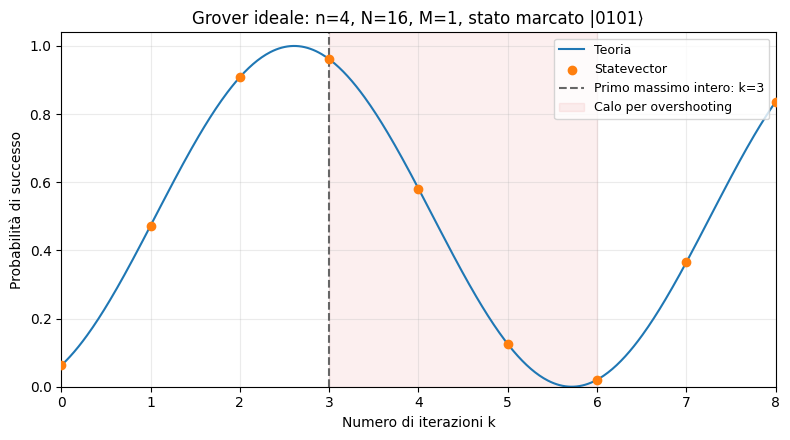

In [24]:
overshooting_df = comparison_df.query("n == 4").sort_values("k")
k_opt = optimal_grover_iterations(16, 1)
assert k_opt == 3
probabilities = overshooting_df.statevector_probability.to_numpy()
assert np.all(np.diff(probabilities[:k_opt + 1]) > 0)
assert np.all(np.diff(probabilities[k_opt:7]) < 0)
assert probabilities[k_opt] > 0.95 and probabilities[6] < 0.03
k_curve = np.linspace(0, 8, 500)
p_curve = np.sin((2 * k_curve + 1) * grover_theta(16, 1)) ** 2
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_curve, p_curve, label="Teoria", color="tab:blue")
ax.scatter(overshooting_df.k, probabilities, label="Statevector", color="tab:orange", zorder=3)
ax.axvline(k_opt, linestyle="--", color="0.4", label=f"Primo massimo intero: k={k_opt}")
ax.axvspan(k_opt, 6, color="tab:red", alpha=0.07, label="Calo per overshooting")
ax.set(xlabel="Numero di iterazioni k", ylabel="Probabilità di successo",
       title="Grover ideale: n=4, N=16, M=1, stato marcato |0101⟩",
       xlim=(0, 8), ylim=(0, 1.04), xticks=range(9))
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

### 15.1 Risultati con shots e scaling delle iterazioni
A: confronto per n=6, con barre di un errore standard binomiale.
B: tutte le misure confrontate con la diagonale di accordo perfetto.
C: il miglior k **osservato nella finestra campionata** per ciascun n viene confrontato
con il k teorico intero e con $(\pi/4)\sqrt N$. In caso di parità scegliamo il k minore.
I punti osservati sono selezionati dalle frequenze, non assegnati dalla teoria: con shots finiti
la scelta può fluttuare. Non attribuiamo al k selezionato una barra binomiale, che riguarda
le probabilità e non l'incertezza sull'argmax. La linea approssimata trascura $-1/2$ e l'arrotondamento.

,n,N,k,theoretical_k_opt,measured_success_probability
1,2,4,1,1,1.0
6,3,8,2,2,0.944092
11,4,16,3,3,0.959473
16,5,32,4,4,0.998779
21,6,64,6,6,0.996094


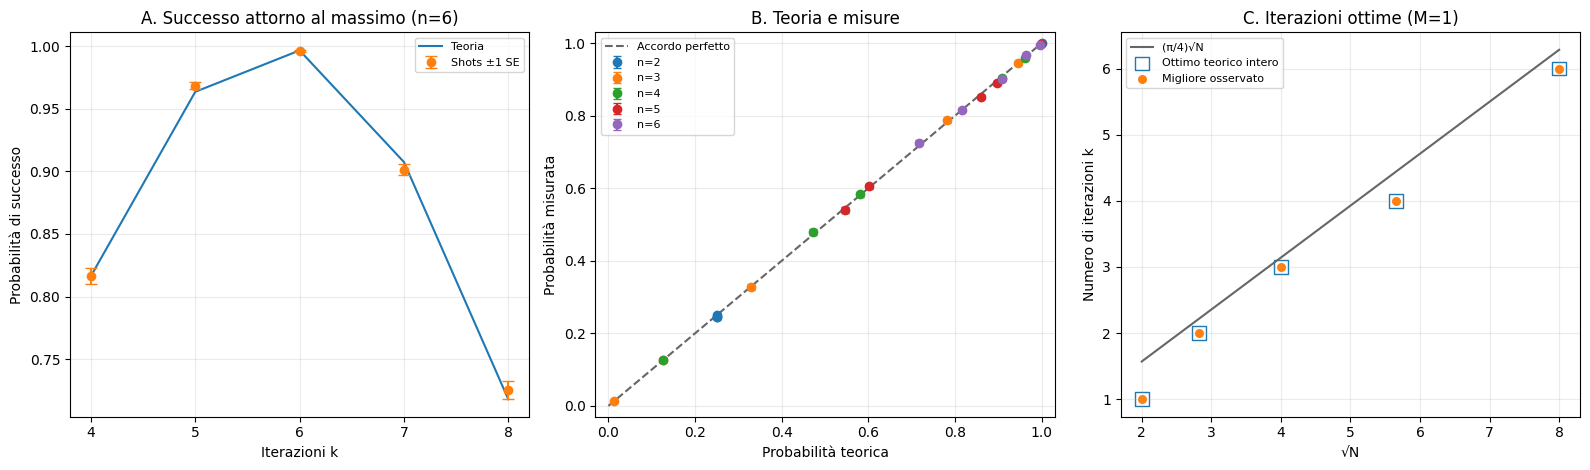

In [25]:
best_observed_df = (ideal_results_df.sort_values(["n", "measured_success_probability", "k"],
                                         ascending=[True, False, True])
                    .groupby("n", sort=True).head(1).sort_values("n").copy())
best_observed_df["theoretical_k_opt"] = [optimal_grover_iterations(int(N), int(M))
                                       for N, M in zip(best_observed_df.N, best_observed_df.M)]
display(best_observed_df[["n", "N", "k", "theoretical_k_opt", "measured_success_probability"]])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sample = ideal_results_df[ideal_results_df.n == 6].sort_values("k")
axes[0].plot(sample.k, sample.theoretical_probability, "-", label="Teoria")
axes[0].errorbar(sample.k.to_numpy(dtype=float), sample.measured_success_probability.to_numpy(dtype=float),
                 yerr=sample.standard_error.to_numpy(dtype=float), fmt="o", capsize=4, label="Shots ±1 SE")
axes[0].set(title="A. Successo attorno al massimo (n=6)", xlabel="Iterazioni k",
            ylabel="Probabilità di successo", xticks=sample.k.to_list())
for n, group in ideal_results_df.groupby("n"):
    axes[1].errorbar(group.theoretical_probability.to_numpy(dtype=float),
                     group.measured_success_probability.to_numpy(dtype=float),
                     yerr=group.standard_error.to_numpy(dtype=float), fmt="o", capsize=3, label=f"n={n}")
axes[1].plot([0, 1], [0, 1], "--", color="0.4", label="Accordo perfetto")
axes[1].set(title="B. Teoria e misure", xlabel="Probabilità teorica",
            ylabel="Probabilità misurata", xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
sqrt_N = np.sqrt(best_observed_df.N.to_numpy(dtype=float))
x_line = np.linspace(sqrt_N.min(), sqrt_N.max(), 100)
axes[2].plot(x_line, np.pi / 4 * x_line, label="(π/4)√N", color="0.4")
axes[2].scatter(sqrt_N, best_observed_df.theoretical_k_opt, marker="s", s=100,
                facecolors="none", edgecolors="tab:blue", label="Ottimo teorico intero")
axes[2].scatter(sqrt_N, best_observed_df.k, color="tab:orange", s=30, label="Migliore osservato")
axes[2].set(title="C. Iterazioni ottime (M=1)", xlabel="√N", ylabel="Numero di iterazioni k")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 16. Conclusioni della verifica ideale
Gli assert confrontano teoria e Statevector per 27 combinazioni di n e k, con una soluzione
e n=2,3,4. Il caso N=4,M=1 raggiunge lo stato marcato dopo una sola iterazione.
Il caso N=16 mostra crescita, primo massimo a k=3 e calo per overshooting.
I controlli aggiuntivi coprono più soluzioni, n=1, zero iterazioni e misure opzionali.
Questi risultati riguardano l'evoluzione ideale esatta; hardware reale resta una fase futura.

### Controlli minimi della struttura
Verifichiamo anche ambiente e schema popolato dalle esecuzioni ideali con shots;
la tabella dei confronti Statevector è comparison_df.

La serie statistica aggiunge 24 esecuzioni da 4096 shots per n=2,...,6. Le frequenze,
le incertezze e il confronto dei massimi osservati sono riportati sopra; i tempi sono
misure lato Python senza interpretazione come tempo fisico della QPU.

La sezione 10 aggiunge 60 esecuzioni noisy e confronti a parità di risorse compilate.
Le tabelle riportano anche gli aumenti locali, distinguendo fluttuazioni da cambiamenti del modello.
Non sono stati eseguiti job su hardware reale.

Le sezioni 11 e 12 aggiungono lo scaling ideale fino a n=7 e 36 confronti con M=1,2,4,8.
Le rispettive tabelle riassumono risorse, tempi Python e probabilità. Gli assert verificano
la diminuzione di k_opt da 4 a 1 al crescere di M, senza confonderla con un risparmio garantito di porte.

In [26]:
assert SHOTS_DEFAULT > 0
assert all(isinstance(n, int) and n > 0 for n in N_VALUES)
validate_problem(N_QUBITS_DEFAULT, MARKED_STATES_DEFAULT)
assert 1 <= N_SOLUTIONS_DEFAULT <= SEARCH_SPACE_SIZE
assert not results_df.empty
assert list(results_df.columns) == list(RESULT_DTYPES)
assert {name: str(dtype) for name, dtype in results_df.dtypes.items()} == RESULT_DTYPES
assert make_results_dataframe() is not results_df
assert np.array_equal(
    np.random.default_rng(RANDOM_SEED).random(4),
    np.random.default_rng(RANDOM_SEED).random(4),
)
assert QuantumCircuit(N_QUBITS_DEFAULT).num_qubits == N_QUBITS_DEFAULT
assert make_ideal_backend().options.seed_simulator == RANDOM_SEED
fig = plt.figure()
plt.close(fig)
print("Controlli minimi superati: ambiente e strutture pronti; verifiche Statevector, shots e CSV completate.")

Controlli minimi superati: ambiente e strutture pronti; verifiche Statevector, shots e CSV completate.
